# 52 -- Chemprop + CheMeleon with the QM data at BOTH the molecule and the per-atom level

Every QM experiment on this project so far has fed the quantum data to a model as **columns of a
table**, and every one has come back negative. Notebook 44 gave Chemprop the molecule-level block
as extra descriptors (`plain_qm`) and got `p_BH = 0.82` on all four isoforms. Notebook 18 did the
same with a charge descriptor and got a clean tie. Notebook 46 ran six tabular QM blocks on the
frozen cluster-disjoint partition and returned `DETECTED_NOT_MATERIAL`, with all ten significant
cells under their materiality bars. Notebook 49 then explained why that strand kept failing: those
blocks correlate **0.995 to 0.997** with a ridge arm carrying no quantum content at all, because
they are 239-column models of which 226 columns are the free 2D descriptors. Thirteen columns
cannot out-shout 226.

**The entire bet of this notebook is that a per-atom feature is a different proposition.** It
attaches to the atom, enters the message passing, and travels to that atom's neighbours. It is not
competing with 226 other columns for a linear model's attention; it changes what the graph says
about a particular nitrogen. That has never been tried here.

The molecule-level half is included because it is free (the same forward pass), and because it
makes this arm a strict superset of `plain_qm` rather than a second, incomparable thing. It is
**not** expected to contribute: notebook 44 already measured it at null.

**The feature set, used identically in stages 1 and 2:**

| level | content | route |
|---|---|---|
| graph | `canonical_smiles`, Chemprop's own atom and bond features, V2 featurizer | `-s canonical_smiles` |
| molecule | notebook 44's **13** genuinely-new QM columns (not the unscreened 18 `plain_qm` used) | `--descriptors-columns` |
| atom | `q_hirshfeld` and `mayer_va`, per atom | `--atom-features-path` |

Deliberately absent: **notebook 45's four aggregate atom descriptors.** They are summaries of these
same per-atom values (`hirshfeld_C_min`, `hirshfeld_H_min`, `bond_order_min`, `mayer_va_min` are all
reductions over the columns this notebook now feeds atom by atom), so passing both would be passing
one quantity twice -- once raw and once pre-reduced -- and would make any effect unattributable.
No bond features either: bond ordering is a second ordering problem and can wait.

**Three stages. This notebook currently contains stage 0 only, and stage 0 ends in a decision
point that is the user's, not mine.**

0. Ordering, features, wiring. The atom ordering is the whole risk, and the wiring check is the
   gate that decides whether stage 1 is worth four to five hours.
1. 25 folds on the frozen cluster-disjoint partition, against notebook 37's stored `plain`.
2. Full-data fit, blind predictions, both correction layers, a validated submission file.

**`SEND` is False throughout and nothing is transmitted.**

## Part 0 -- setup and provenance

In [1]:
# Part 0.1 -- setup, provenance, and the environment assertions this project requires.
import hashlib, importlib.util, json, os, re, subprocess, sys, textwrap, warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

# Notebook 34 established that restricting BLAS/OMP to one thread changes floating-point
# reduction order and so chemprop's training trajectory. OMP_NUM_THREADS is ASSERTED unset;
# KMP_DUPLICATE_LIB_OK is only REPORTED, because `import xgboost` sets it and an assertion
# after imports is unsatisfiable (notebook 40's own re-run bug).
assert os.environ.get("OMP_NUM_THREADS") is None, "OMP_NUM_THREADS must be unset"
print("OMP_NUM_THREADS      : unset (asserted)")
print(f"KMP_DUPLICATE_LIB_OK : {os.environ.get('KMP_DUPLICATE_LIB_OK')!r} (reported, not asserted)")

SEND = False
print(f"SEND                 : {SEND}  (nothing is transmitted anywhere in this notebook)")

OUT = REPO / "outputs" / "52_chemprop_qm_atom_features"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
NB37 = REPO / "outputs" / "37_butina_5x5_complete"
NB44 = REPO / "outputs" / "44_qm_molecular_block"
NB45 = REPO / "outputs" / "45_atom_level_screen"
NB46 = REPO / "outputs" / "46_qm_arm"
QM_PARSED = REPO / "outputs" / "qm_parsed"
CURATED = REPO / "data" / "processed" / "train_inhibition_curated.csv"
BLIND = REPO / "data" / "processed" / "test_blinded_curated.csv"
BUTINA = REPO / "data" / "folds" / "cv_folds_butina_5x5.csv"
NB34_FOLD_SHA256 = "52f39b1a1cea9200b58dce0a061d4a21ce94d9d58ec77067cf6508b0f4b3e87e"

ISOFORMS = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]
EP = {i: f"{i}_pIC50_direct_inhibition" for i in ISOFORMS}

RUN_STARTED_AT = datetime.now(timezone.utc)
_pre = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
PRE_DIRTY = sorted(l[3:].strip() for l in _pre.stdout.splitlines() if not l.startswith("??"))
(OUT / "run_meta.json").write_text(json.dumps(
    {"run_started_at_utc": RUN_STARTED_AT.isoformat(), "pre_existing_dirty_tracked_paths": PRE_DIRTY,
     "send": SEND}, indent=2) + "\n")


def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for c in iter(lambda: f.read(1 << 20), b""):
            h.update(c)
    return h.hexdigest()


assert sha256(BUTINA) == NB34_FOLD_SHA256, "the frozen partition is not the file 34/35/37 ran on"
print(f"\ncv_folds_butina_5x5.csv sha256 asserted against notebook 34's record: MATCH")

import chemprop
CP = Path(chemprop.__file__).parent
print(f"chemprop             : {chemprop.__version__} at {CP}")
print(f"run started          : {RUN_STARTED_AT.isoformat(timespec='seconds')}")
print(f"pre-existing dirty tracked paths (subtracted by the scope check): {len(PRE_DIRTY)}")

OMP_NUM_THREADS      : unset (asserted)
KMP_DUPLICATE_LIB_OK : None (reported, not asserted)
SEND                 : False  (nothing is transmitted anywhere in this notebook)

cv_folds_butina_5x5.csv sha256 asserted against notebook 34's record: MATCH


chemprop             : 2.3.1 at /Users/codiefreeman/miniconda3-arm64/envs/cyp-admet-v2/lib/python3.11/site-packages/chemprop
run started          : 2026-10-11T22:25:23+00:00
pre-existing dirty tracked paths (subtracted by the scope check): 14


### Part 0.2 -- the premise the brief could not have known: CheMeleon refuses per-atom features

The task specifies CheMeleon **and** per-atom features. In chemprop 2.3.1 those two are mutually
exclusive through the documented route, and the refusal is explicit rather than a silent failure.

The cell below establishes this three ways: from chemprop's own source, from the published
checkpoint's weight shapes, and from a real CLI invocation.

In [2]:
# Part 0.2 -- the refusal, from chemprop's source, the checkpoint, and a live CLI call.
train_src = (CP / "cli" / "train.py").read_text()

# (a) the source. The guard and the three arguments it refuses.
i = train_src.index("case FoundationModels.CHEMELEON:")
block = train_src[train_src.rindex("if not local_foundation:", 0, i):i + 1400]
print("chemprop/cli/train.py, the CheMeleon-specific validation:\n")
print(textwrap.indent("\n".join(l for l in block.splitlines()
                                if "atom_features_path" in l or "atom_descriptors_path" in l
                                or "bond_features_path" in l or "does not support" in l
                                or "local_foundation" in l), "    "))
assert "CheMeleon does not support passing" in block

# The guard is `if not local_foundation:` -- so the refusal applies to the model NAME only.
assert "if not local_foundation:" in train_src

# (b) the published checkpoint. The reason the refusal is structural rather than arbitrary.
import torch
CKPT = Path.home() / ".chemprop" / "chemeleon_mp.pt"
ck = torch.load(CKPT, weights_only=True)
hp, sd = ck["hyper_parameters"], ck["state_dict"]
print(f"\n\nCheMeleon's published checkpoint ({CKPT.name}, sha256 {sha256(CKPT)[:16]}):")
print(f"  hyper_parameters : d_v={hp['d_v']} d_e={hp['d_e']} d_h={hp['d_h']} "
      f"depth={hp['depth']} d_vd={hp['d_vd']}")
for k, v in sd.items():
    print(f"  {k:12s} {tuple(v.shape)}")
from chemprop.featurizers import MultiHotAtomFeaturizer
assert len(MultiHotAtomFeaturizer.v2()) == hp["d_v"] == 72
print(f"\n  W_i is (d_h, d_v + d_e) = (2048, {hp['d_v']} + {hp['d_e']}) = "
      f"{tuple(sd['W_i.weight'].shape)}, and the V2 atom featurizer is exactly {hp['d_v']} wide.")
print("  So one extra atom feature widens an input the pretrained projection cannot accept.")

# (c) a real CLI call, so this is not an argument from reading code.
TMP = OUT / "flag_probe"; TMP.mkdir(parents=True, exist_ok=True)
smis = ["CCO", "c1ccccc1", "CC(=O)O", "CCN", "CCCl", "c1ccncc1", "CC(C)O", "CCBr"]
pd.DataFrame({"smiles": smis, "y": np.linspace(4, 6, len(smis)),
              "sp": ["train"] * 6 + ["val"] * 2}).to_csv(TMP / "probe.csv", index=False)
from rdkit import Chem, RDLogger
RDLogger.DisableLog("rdApp.*")
np.savez(TMP / "probe_atoms.npz",
         *[np.random.RandomState(0).randn(Chem.MolFromSmiles(s).GetNumAtoms(), 2) for s in smis])
BASE = ["chemprop", "train", "-i", str(TMP / "probe.csv"), "-s", "smiles",
        "--target-columns", "y", "--splits-column", "sp", "-t", "regression",
        "--multi-hot-atom-featurizer-mode", "V2", "--epochs", "5", "--patience", "5",
        "--accelerator", "cpu", "--devices", "1"]
r = subprocess.run(BASE + ["--from-foundation", "CHEMELEON",
                           "--atom-features-path", str(TMP / "probe_atoms.npz"),
                           "-o", str(TMP / "named")], capture_output=True, text=True)
err = [l for l in (r.stdout + r.stderr).splitlines() if "ArgumentError" in l or "does not support" in l]
print(f"\n\n`--from-foundation CHEMELEON --atom-features-path ...` exits {r.returncode}:")
for l in err:
    print("   ", l.strip())
assert r.returncode != 0 and any("does not support passing --atom-features-path" in l for l in err)
print("\nCONFIRMED empirically, not inferred. The documented route is closed.")

chemprop/cli/train.py, the CheMeleon-specific validation:

    if not local_foundation:
                            (args.atom_features_path, "--atom-features-path"),
                            (args.atom_descriptors_path, "--atom-descriptors-path"),
                            (args.bond_features_path, "--bond-features-path"),
                                    message=f"CheMeleon does not support passing {arg_name}",


CheMeleon's published checkpoint (chemeleon_mp.pt, sha256 c376624d3407204e):
  hyper_parameters : d_v=72 d_e=14 d_h=2048 depth=6 d_vd=None
  W_i.weight   (2048, 86)
  W_h.weight   (2048, 2048)
  W_o.weight   (2048, 2120)
  W_o.bias     (2048,)

  W_i is (d_h, d_v + d_e) = (2048, 72 + 14) = (2048, 86), and the V2 atom featurizer is exactly 72 wide.
  So one extra atom feature widens an input the pretrained projection cannot accept.




`--from-foundation CHEMELEON --atom-features-path ...` exits 1:
    raise ArgumentError(
    argparse.ArgumentError: CheMeleon does not support passing --atom-features-path

CONFIRMED empirically, not inferred. The documented route is closed.


### Part 0.3 -- which flag, decided from chemprop 2.3.1's behaviour rather than from the paper

The brief asks which of `--atom-features-path` and `--atom-descriptors-path` puts values **into**
message passing. The help strings say "before" and "after", but a help string is documentation; the
cell below reads the two code paths the tensors actually travel.

In [3]:
# Part 0.3 -- V_f enters before W_i; V_d is concatenated after the last message passing step.
mol_src = (CP / "featurizers" / "molgraph" / "molecule.py").read_text()
mix_src = (CP / "nn" / "message_passing" / "mixins.py").read_text()
base_src = (CP / "nn" / "message_passing" / "base.py").read_text()

print("--atom-features-path  ->  V_f  ->  featurizers/molgraph/molecule.py")
for l in mol_src.splitlines():
    if "atom_features_extra" in l and ("hstack" in l or "torch.cat" in l):
        print("   ", l.strip())
assert "V = np.hstack((V, atom_features_extra))" in mol_src
print("    ...the extra columns are hstacked onto the atom feature matrix V, so d_v grows.")

print("\n    nn/message_passing/mixins.py -- what W_i is applied to:")
for l in mix_src.splitlines():
    if "self.W_i" in l:
        print("   ", l.strip())
assert "self.W_i(torch.cat([bmg.V[bmg.edge_index[0]], bmg.E], dim=1))" in mix_src
print("    So V_f is inside the FIRST projection and every one of the 6 message passing steps.")

print("\n--atom-descriptors-path  ->  V_d  ->  nn/message_passing/base.py::finalize")
fin = base_src[base_src.index("    def finalize("):]
fin = fin[:fin.index("    def forward(")]
for l in fin.splitlines():
    if "W_o(" in l or "W_d(" in l:
        print("   ", l.strip())
assert "H = self.W_o(torch.cat((V, M), dim=1))" in fin
assert "H = self.W_d(torch.cat((H, V_d), dim=1))" in fin
print("    `finalize` runs ONCE, after the message passing loop, on the final messages M.")
print("    V_d therefore never reaches a neighbouring atom. It is a per-atom read-out, not an input.")

DECISION_FLAG = "--atom-features-path"
print(f"\nDECISION: {DECISION_FLAG}. It is the only one of the two that enters message passing,")
print("which is the entire mechanism this notebook is testing.")

--atom-features-path  ->  V_f  ->  featurizers/molgraph/molecule.py
    V = np.hstack((V, atom_features_extra))
    atom_feats = torch.cat((atom_feats, atom_features_extra), dim=1)
    ...the extra columns are hstacked onto the atom feature matrix V, so d_v grows.

    nn/message_passing/mixins.py -- what W_i is applied to:
    return self.W_i(torch.cat([bmg.V[bmg.edge_index[0]], bmg.E], dim=1))
    return self.W_i(bmg.V[bmg.edge_index[0]])
    So V_f is inside the FIRST projection and every one of the 6 message passing steps.

--atom-descriptors-path  ->  V_d  ->  nn/message_passing/base.py::finalize
    H = self.W_o(torch.cat((V, M), dim=1))  # V x d_o
    H = self.W_d(torch.cat((H, V_d), dim=1))  # V x (d_o + d_vd)
    `finalize` runs ONCE, after the message passing loop, on the final messages M.
    V_d therefore never reaches a neighbouring atom. It is a per-atom read-out, not an input.

DECISION: --atom-features-path. It is the only one of the two that enters message passing,
whi

### Part 0.4 -- the route through, and a scaling defect it exposes

`if not local_foundation:` guards the refusal, so it applies to the foundation model's **name**, not
to a local file; and the local path takes only `message_passing` and `agg` from that file. So the
route through is to write a local foundation file holding **CheMeleon's own weights with two extra
columns of zeros** inserted where the featurizer appends the extra features. At initialisation the
result is numerically identical to CheMeleon for any value of those features, because their weights
are exactly zero -- the pretrained encoder is preserved bit for bit, and the only new parameters
are the two columns, which training can then move off zero.

Taking that route surfaced a second, more dangerous thing, which is the reason this notebook scales
the per-atom values itself.

In [4]:
# Part 0.4a -- the widened encoder, and its at-init identity with CheMeleon.
aa_spec = importlib.util.spec_from_file_location("nb52_atom_arrays",
                                                 REPO / "scripts" / "52_atom_arrays.py")
aa = importlib.util.module_from_spec(aa_spec); aa_spec.loader.exec_module(aa)

# Stage 0 ran k=2. The file is rebuilt here rather than read back, because it is a gitignored
# derived artefact and because the point of the check is that the construction is sound at any k
# -- stage 1a repeats it at k=3.
enc = aa.build_widened_chemeleon(2)
print("the widened local foundation file (k=2, the set stage 0 ran on):")
for k in ("k", "d_v_original", "d_v_widened", "W_i_shape", "W_o_shape",
          "max_abs_diff_vs_chemeleon_at_init"):
    print(f"  {k:36s} {enc[k]}")
assert enc["max_abs_diff_vs_chemeleon_at_init"] == 0.0
print("\n  The at-init check is run on a real molecule with RANDOM extra feature values, so it")
print("  cannot pass merely because the features happened to be zero. 0.0 exactly.")
print("  `agg` is MeanAggregation, matching what the remote CheMeleon path builds -- the local")
print("  path reads agg from the file, so it has to be set deliberately.")

the widened local foundation file (k=2, the set stage 0 ran on):
  k                                    2
  d_v_original                         72
  d_v_widened                          74
  W_i_shape                            [2048, 88]
  W_o_shape                            [2048, 2122]
  max_abs_diff_vs_chemeleon_at_init    0.0

  The at-init check is run on a real molecule with RANDOM extra feature values, so it
  cannot pass merely because the features happened to be zero. 0.0 exactly.
  `agg` is MeanAggregation, matching what the remote CheMeleon path builds -- the local
  path reads agg from the file, so it has to be set deliberately.


In [5]:
# Part 0.4b -- THE SCALING DEFECT. chemprop computes an atom-feature scaler, logs it, and then
# fails to attach it to a foundation-loaded encoder. Training is scaled; predict is not.
print("cli/train.py -- the scaler is fitted on the TRAIN split only:")
for l in train_src.splitlines():
    if 'normalize_inputs("V_f"' in l or "Atom features for mol" in l:
        print("   ", l.strip())

print("\n...and `graph_transform=` is assigned ONLY in the non-foundation branch:")
for n, l in enumerate(train_src.splitlines(), 1):
    if "graph_transform=graph_transforms[" in l:
        print(f"    line {n}: {l.strip()}")
nofound = train_src[train_src.index("    else:\n        mp_cls = AtomMessagePassing"):]
assert "graph_transform=graph_transforms[0]" in nofound
found = train_src[train_src.index("    if args.from_foundation is not None:"):
                  train_src.index("    else:\n        mp_cls = AtomMessagePassing")]
assert "graph_transform" not in found, "the foundation branch would have to assign it"
print("    The foundation branch contains no `graph_transform` assignment at all.")

print("\ndatasets.py -- normalize_inputs MUTATES the training arrays in place:")
ds = (CP / "data" / "datasets.py").read_text()
assert 'self.V_fs = [scaler.transform(V_f) if V_f.size > 0 else V_f for V_f in self._V_fs]' in ds
print('    self.V_fs = [scaler.transform(V_f) ... for V_f in self._V_fs]')
print("    so TRAINING sees scaled features while the saved checkpoint carries nn.Identity,")
print("    and `chemprop predict` therefore feeds the same features UNSCALED.")

# Demonstrated on two real checkpoints, both written by a CLI run in this notebook's own fixture.
from chemprop.models import MPNN
for tag, extra in [("foundation", ["--from-foundation", str(aa.foundation_path(2))]),
                   ("no-foundation", [])]:
    d = TMP / f"gt_{tag.replace('-', '_')}"
    if not (d / "model_0" / "best.pt").exists():
        subprocess.run(BASE + extra + ["--atom-features-path", str(TMP / "probe_atoms.npz"),
                                       "-o", str(d)], capture_output=True, text=True)
    gt = MPNN.load_from_file(d / "model_0" / "best.pt", map_location="cpu").message_passing \
        .graph_transform
    inner = type(getattr(gt, "V_transform", None)).__name__ if hasattr(gt, "V_transform") else "-"
    print(f"\n  {tag:14s} checkpoint graph_transform = {type(gt).__name__:15s} V_transform = {inner}")
    if tag == "foundation":
        assert type(gt).__name__ == "Identity"
    else:
        assert type(gt).__name__ == "GraphTransform"

print("\nCONSEQUENCE, and the decision it forces: a silent train/predict mismatch on every blind")
print("prediction. This notebook therefore passes --no-atom-feature-scaling and standardises the")
print("per-atom values itself, from the fold's screen_inner_train atoms only -- the population")
print("chemprop's own scaler would have used, excluding the inner validation set and the held-out")
print("fold. Explicit, auditable, and identical at train and predict time.")

cli/train.py -- the scaler is fitted on the TRAIN split only:
    scaler = train_dset.normalize_inputs("V_f")
    val_dset.normalize_inputs("V_f", scaler)
    f"Atom features for mol {i}: loc = {np.array2string(scaler.mean_, precision=3)}, scale = {np.array2string(scaler.scale_, precision=3)}"
    train_dsets[i].normalize_inputs("V_f", scaler)
    val_dsets[i].normalize_inputs("V_f", scaler)

...and `graph_transform=` is assigned ONLY in the non-foundation branch:
    line 1530: graph_transform=graph_transforms[i],
    line 1556: graph_transform=graph_transforms[0],
    line 1640: graph_transform=graph_transforms[0],
    The foundation branch contains no `graph_transform` assignment at all.

datasets.py -- normalize_inputs MUTATES the training arrays in place:
    self.V_fs = [scaler.transform(V_f) ... for V_f in self._V_fs]
    so TRAINING sees scaled features while the saved checkpoint carries nn.Identity,
    and `chemprop predict` therefore feeds the same features UNSCALED.

  foun

## Part 1 -- the atom ordering, which is the whole risk

The QM run featurised every compound as `Chem.AddHs(Chem.MolFromSmiles(row.SMILES))` -- the **raw**
`SMILES` column -- and wrote atoms in RDKit's native index order. Chemprop, as this project runs it,
is given `-s canonical_smiles`. Feeding a per-atom array in ORCA's order to a graph built from
`canonical_smiles` would put Hirshfeld charges on the wrong atoms, on a quarter of the library,
with nothing raising.

`scripts/52_build_atom_ordering.py` builds the permutation and verifies it. Both molecules are
routed through the same `Chem.MolToSmiles` call, which records `_smilesAtomOutputOrder`: position
*k* of the shared canonical string is raw atom `o_raw[k]` and canonical atom `o_can[k]`, so chemprop
atom `o_can[k]` is ORCA atom `o_raw[k]`. Going through one canonicalisation rather than matching the
two orderings against each other is what makes it robust to symmetry -- RDKit's own tie-breaking
decides, identically on both sides.

In [6]:
# Part 1.1 -- the ordering verification, read from the script's own saved report.
rep = json.loads((OUT / "ordering_verification.json").read_text())
order = pd.read_csv(OUT / "atom_ordering.csv")
n = rep["n_compounds"]
assert n == 5655 == len(order) and rep["n_train"] == 4905 and rep["n_blind"] == 750

print(f"{n} compounds ({rep['n_train']} train + {rep['n_blind']} blind)\n")
checks = [
    ("AddHs preserves heavy-atom indices", rep["addhs_preserves_heavy_indices"]),
    ("the permutation is a bijection", rep["bijection"]),
    ("element at chemprop j == element at ORCA perm[j]", rep["element_sequence_under_permutation"]),
    ("  the same check against qm_atoms.csv itself", rep["element_sequence_against_qm_atoms_csv"]),
    ("chemprop bonds map into ORCA's bond set", rep["bond_subset_under_permutation"]),
]
for label, got in checks:
    print(f"  {label:52s} {got}/{n}   {'PASS' if got == n else 'FAIL'}")
    assert got == n
print(f"\n  negative control (two entries swapped) REJECTED on "
      f"{rep['negative_control_rejected']}/{rep['negative_control_probes']} probes")
assert rep["negative_control_rejected"] >= 1, "the assertions would be vacuous"
print("  -- without this the checks above could all be trivially true. They are not.")

print(f"\n  the permutation is the IDENTITY on {rep['permutation_is_identity']}/{n} "
      f"({100 * rep['permutation_is_identity'] / n:.1f}%),")
print(f"  so it does real work on {rep['permutation_does_work_on']} compounds.")
print(f"\n  cross-check: canonical_smiles reproduces ORCA's element sequence on "
      f"{rep['canonical_smiles_element_sequence_matches']}/{n},")
print(f"  against notebook 43's recorded {rep['nb43_recorded_element_sequence_matches']}: "
      f"{'MATCH' if rep['canonical_smiles_element_sequence_matches'] == rep['nb43_recorded_element_sequence_matches'] else 'DIFFERS'}")
assert rep["canonical_smiles_element_sequence_matches"] == rep["nb43_recorded_element_sequence_matches"]

5655 compounds (4905 train + 750 blind)

  AddHs preserves heavy-atom indices                   5655/5655   PASS
  the permutation is a bijection                       5655/5655   PASS
  element at chemprop j == element at ORCA perm[j]     5655/5655   PASS
    the same check against qm_atoms.csv itself         5655/5655   PASS
  chemprop bonds map into ORCA's bond set              5655/5655   PASS

  negative control (two entries swapped) REJECTED on 50/50 probes
  -- without this the checks above could all be trivially true. They are not.

  the permutation is the IDENTITY on 4112/5655 (72.7%),
  so it does real work on 1543 compounds.

  cross-check: canonical_smiles reproduces ORCA's element sequence on 4212/5655,
  against notebook 43's recorded 4212: MATCH


In [7]:
# Part 1.2 -- what chemprop's graph can and cannot carry, and an independent hydrogen cross-check.
h_drop, total, heavy = (rep["hydrogen_rows_dropped"], rep["orca_atom_rows_total"],
                        rep["heavy_atom_rows_used"])
assert h_drop + heavy == total
print(f"ORCA atom rows                 {total:>8,}")
print(f"  heavy atoms, USED            {heavy:>8,}  ({100 * heavy / total:.1f}%)")
print(f"  hydrogens, DROPPED           {h_drop:>8,}  ({100 * h_drop / total:.1f}%)")
print("\nChemprop does not add hydrogens -- its own resolved args carry add_h=False, keep_h=False --")
print("so its graph has no vertex for a hydrogen to attach a feature to. That is a real loss of")
print("information this notebook cannot recover, and it is stated rather than worked around.")

# Notebook 45's finding 5 recorded 113,596 nulls in the shell-population columns, "exactly the
# hydrogen count". That figure was derived from the QM table's missingness; this one from RDKit
# valence. Two independent routes to the same number.
NB45_SHELL_NULLS = 113596
print(f"\ncross-check: notebook 45's finding 5 recorded {NB45_SHELL_NULLS:,} nulls in the shell-")
print(f"population columns, 'exactly the hydrogen count'. This notebook's hydrogen count, derived")
print(f"independently from RDKit valence rather than from missingness: {h_drop:,}  "
      f"{'MATCH' if h_drop == NB45_SHELL_NULLS else 'DIFFERS'}")
assert h_drop == NB45_SHELL_NULLS
print("That is also precisely why the two chosen columns are q_hirshfeld and mayer_va: both are")
print("defined on every atom, so no hydrogen-null policy is needed anywhere.")

ORCA atom rows                  252,237
  heavy atoms, USED             138,641  (55.0%)
  hydrogens, DROPPED            113,596  (45.0%)

Chemprop does not add hydrogens -- its own resolved args carry add_h=False, keep_h=False --
so its graph has no vertex for a hydrogen to attach a feature to. That is a real loss of
information this notebook cannot recover, and it is stated rather than worked around.

cross-check: notebook 45's finding 5 recorded 113,596 nulls in the shell-
population columns, 'exactly the hydrogen count'. This notebook's hydrogen count, derived
independently from RDKit valence rather than from missingness: 113,596  MATCH
That is also precisely why the two chosen columns are q_hirshfeld and mayer_va: both are
defined on every atom, so no hydrogen-null policy is needed anywhere.


## Part 2 -- the features, and the .npz arrays

Two builders, both in `scripts/` as the brief requires, so the notebook never rebuilds them inline
and stage 2 cannot drift from stage 1.

In [8]:
# Part 2.1 -- the 13 molecule-level columns, re-derived from QM_FULL rather than typed.
run_spec = importlib.util.spec_from_file_location("nb52_runner",
                                                  REPO / "scripts" / "52_run_qm_atom_arms.py")
runner = importlib.util.module_from_spec(run_spec); run_spec.loader.exec_module(runner)

qm = pd.read_csv(NB44 / "features" / "QM_FULL.csv")
THIRTEEN = runner.thirteen_qm_columns(qm)
print(f"QM_FULL carries {len([c for c in qm.columns if c not in ('Molecule_Name','inchikey','split')])}"
      f" value columns; 5 are algebraic derivatives of the others, leaving {len(THIRTEEN)}:")
for c in THIRTEEN:
    print("   ", c)
print(f"\nexcluded as derived: {runner.DERIVED5}")
assert len(THIRTEEN) == 13 and len(qm) == 5655
print(f"\ncoverage: {len(qm)} compounds, nulls {int(qm[THIRTEEN].isna().sum().sum())}")

# The cross-check that matters: this is the same 13 notebook 46 used, so `plain_qm`'s molecule-level
# half here is the block that has already been measured rather than a new one.
nb46_qm13 = pd.read_csv(NB46 / "features" / "FREE_QM13.csv", nrows=0).columns
assert set(THIRTEEN) <= set(nb46_qm13), "not notebook 46's own 13"
print("asserted identical to the 13 inside notebook 46's own FREE_QM13 block.")

S0 = aa.ATOM_FEATURE_COLS_STAGE0
print(f"\nper-atom columns AT STAGE 0: {S0}  (k = {len(S0)}; stage 1a adds a third)")
NB45_FOUR = ["hirshfeld_C_min", "hirshfeld_H_min", "bond_order_min", "mayer_va_min"]
print(f"NOT included -- notebook 45's four aggregates: {NB45_FOUR}")
print("Each is a reduction over exactly the per-atom columns above (a per-element minimum of")
print("q_hirshfeld, or a minimum of mayer_va / bond order), so feeding both would feed one")
print("quantity twice and make any effect unattributable between the raw and reduced forms.")

# A cross-check the brief did not ask for, and the best independent support for the column
# choice: notebook 45's label-free screen ranked every aggregate by how well a model on the
# free 2D descriptors can RECOVER it. Its strong tier at full blind coverage is these four --
# and three of the four are reductions of the two columns fed per-atom here.
v45 = pd.read_csv(NB45 / "verdict_table.csv")
strong = v45[(v45.tier == "strong") & (v45.pct_blind > 99)]
assert sorted(strong.descriptor) == sorted(NB45_FOUR)
print("\nnotebook 45's strong tier at full blind coverage, by 2D-recoverability (lower = less")
print("recoverable from the free 226 descriptors):")
for r in strong.sort_values("read1_axisA").itertuples():
    srcs = {"hirshfeld_C_min": "q_hirshfeld", "hirshfeld_H_min": "q_hirshfeld",
            "mayer_va_min": "mayer_va", "bond_order_min": "(a BOND quantity -- out of scope)"}
    print(f"  {r.descriptor:16s} axis-A R2 {r.read1_axisA:.4f}   reduction of {srcs[r.descriptor]}")
print("\nSo the two per-atom columns chosen here are the raw sources of 3 of the 4 descriptors")
print("notebook 45's own screen found LEAST recoverable from 2D. The fourth is a bond quantity,")
print("which this notebook excludes. The column choice is not arbitrary: it is the same evidence")
print("notebook 45 used, applied one level further down, before the reduction throws the")
print("per-atom structure away.")

QM_FULL carries 18 value columns; 5 are algebraic derivatives of the others, leaving 13:
    dft_homo_ev
    dft_lumo_ev
    homo1_ev
    homo2_ev
    lumo1_ev
    gfn2_homo_ev
    gfn2_lumo_ev
    dft_dipole_debye
    gfn2_relaxation_strain_eh
    npr1
    npr2
    radius_of_gyration
    I1

excluded as derived: ['dft_gap_ev', 'gfn2_gap_ev', 'chi_electronegativity', 'omega_electrophilicity', 'dft_minus_gfn2_gap']

coverage: 5655 compounds, nulls 0
asserted identical to the 13 inside notebook 46's own FREE_QM13 block.

per-atom columns AT STAGE 0: ['q_hirshfeld', 'mayer_va']  (k = 2; stage 1a adds a third)
NOT included -- notebook 45's four aggregates: ['hirshfeld_C_min', 'hirshfeld_H_min', 'bond_order_min', 'mayer_va_min']
Each is a reduction over exactly the per-atom columns above (a per-element minimum of
q_hirshfeld, or a minimum of mayer_va / bond order), so feeding both would feed one
quantity twice and make any effect unattributable between the raw and reduced forms.

notebook 4

In [9]:
# Part 2.2 -- the per-atom matrices, and the per-fold scaler actually used by the wiring fits.
src = aa.AtomFeatureSource(aa.ATOM_FEATURE_COLS_STAGE0)   # the set stage 0 ran on
n_atoms = sum(m.shape[0] for m in src.matrices.values())
print(f"per-atom matrices: {len(src.matrices)} compounds, {n_atoms:,} heavy-atom rows, "
      f"{src.k} features {src.cols}")
assert len(src.matrices) == 5655 and n_atoms == heavy

# src.cols, not aa.ATOM_FEATURE_COLS: stage 1a adds a DERIVED column that is not a
# column of qm_atoms.csv, and this cell is reporting what stage 0 actually ran on.
raw = pd.read_csv(QM_PARSED / "qm_atoms.csv", usecols=["element"] + src.cols)
print("\nunscaled distributions over all 252,237 ORCA atoms, and over the heavy atoms used:")
stk = np.concatenate([src.matrices[k] for k in sorted(src.matrices)], axis=0)
for j, c in enumerate(src.cols):
    print(f"  {c:12s} all atoms  mean {raw[c].mean():8.4f}  sd {raw[c].std(ddof=0):7.4f}   "
          f"heavy only  mean {stk[:, j].mean():8.4f}  sd {stk[:, j].std(ddof=0):7.4f}")

sc = json.loads((OUT / "chemprop_runs" / "wiring_qm_both__r0f0" / "atom_scaler.json").read_text())
print(f"\nthe scaler the wiring fit used, fitted on {sc['n_fit_compounds']} screen_inner_train "
      f"compounds only:")
for c, lo, s in zip(sc["columns"], sc["loc"], sc["scale"]):
    print(f"  {c:12s} loc {lo:9.5f}   scale {s:9.5f}")
print("\nIt excludes the inner validation set and the held-out fold by construction, because it is")
print("fitted from a compound list rather than from the training CSV. A scaler fitted on the")
print("pooled train+val rows would differ, and the next cell's npz summary shows the pooled")
print("rows do NOT come out at exactly mean 0 / sd 1 -- which is the evidence of that exclusion.")

per-atom matrices: 5655 compounds, 138,641 heavy-atom rows, 2 features ['q_hirshfeld', 'mayer_va']

unscaled distributions over all 252,237 ORCA atoms, and over the heavy atoms used:
  q_hirshfeld  all atoms  mean   0.0000  sd  0.0943   heavy only  mean  -0.0310  sd  0.1161
  mayer_va     all atoms  mean   2.4184  sd  1.4150   heavy only  mean   3.6095  sd  0.7015

the scaler the wiring fit used, fitted on 3335 screen_inner_train compounds only:
  q_hirshfeld  loc  -0.03089   scale   0.11511
  mayer_va     loc   3.61252   scale   0.69977

It excludes the inner validation set and the held-out fold by construction, because it is
fitted from a compound list rather than from the training CSV. A scaler fitted on the
pooled train+val rows would differ, and the next cell's npz summary shows the pooled
rows do NOT come out at exactly mean 0 / sd 1 -- which is the evidence of that exclusion.


## Part 3 -- the wiring check

This is the gate. Two fits on one Butina fold, **identical in every respect except the values inside
the atom `.npz`** -- the real standardised values against all zeros. Same widened encoder, same CLI,
same 13 molecule descriptors, same seed, same folds, same code path. If the predictions do not
differ, the values are not reaching the model and stage 1 would spend four to five hours training an
expensive copy of `plain`.

An all-zeros control is a sharper test than simply dropping the flag: dropping it would also change
the encoder and the command line, so a difference could come from anywhere.

In [10]:
# Part 3.1 -- the wiring result.
wv = json.loads((OUT / "wiring_verdict.json").read_text())
wt = pd.read_csv(OUT / "wiring_check.csv")
wt["isoform"] = wt["Endpoint"].str.split("_").str[0]
print(f"arms compared: {wv['arms'][0]} against {wv['arms'][1]}")
print("the ONLY difference between the two runs is the npz contents (real against all-zeros)\n")
print(wt[["set", "isoform", "n", "max_abs_diff", "mean_abs_diff", "pearson"]]
      .to_string(index=False, float_format=lambda v: f"{v:.6f}"))
print(f"\nmax abs difference on the blind 750 : {wv['blind_max_abs_diff']:.6f}")
print(f"max abs difference on the held-out  : {wv['heldout_max_abs_diff']:.6f}")
assert wv["wired"], "NOT WIRED -- the per-atom values are not reaching the model"
print(f"\nWIRED. The per-atom values change the predictions, so stage 1 would be measuring")
print("something real rather than retraining `plain` at expense.")

tim = pd.read_csv(OUT / "run_timings.csv")
w = tim[tim["arm"].str.startswith("wiring_")]
print(f"\nwiring fits: {len(w)} runs, {w['wall_min'].sum():.1f} min total, "
      f"{w['wall_min'].mean():.1f} min/fit, epochs {sorted(w['last_epoch'].dropna().astype(int))}")

arms compared: qm_both against qm_both_zeroatoms
the ONLY difference between the two runs is the npz contents (real against all-zeros)

    set isoform   n  max_abs_diff  mean_abs_diff  pearson
  blind  CYP1A2 750      0.776612       0.141699 0.978446
  blind  CYP2C9 750      0.515590       0.104024 0.986833
  blind  CYP2D6 750      0.614280       0.120990 0.972928
  blind  CYP3A4 750      0.561783       0.131050 0.987630
heldout  CYP1A2 981      0.839736       0.151716 0.968955
heldout  CYP2C9 981      0.404993       0.102218 0.984065
heldout  CYP2D6 981      0.521318       0.125165 0.954957
heldout  CYP3A4 981      0.628823       0.127604 0.984216

max abs difference on the blind 750 : 0.776612
max abs difference on the held-out  : 0.839736

WIRED. The per-atom values change the predictions, so stage 1 would be measuring
something real rather than retraining `plain` at expense.

wiring fits: 2 runs, 30.6 min total, 15.3 min/fit, epochs [18, 25]


In [11]:
# Part 3.1b -- the cost of stage 1, measured here rather than projected. The brief asked for the
# rate after three folds so the estimate could be corrected early; the wiring fits are on the same
# partition and fold and already give a better one, before any CV is committed to.
per_fit = w["wall_min"].to_numpy()
per_epoch = (w["wall_min"] / w["last_epoch"]).to_numpy()
print(f"measured per fit  : {per_fit.min():.2f} to {per_fit.max():.2f} min "
      f"(mean {per_fit.mean():.2f}), at {per_epoch.mean():.3f} min/epoch")
print(f"epoch counts      : {sorted(w['last_epoch'].astype(int))} -- set by early stopping, so "
      f"wall time per fold is NOT like-for-like between runs")
print(f"\nstage 1 is 25 folds of one arm:")
print(f"  at the MEAN fit  : {25 * per_fit.mean() / 60:.1f} h")
print(f"  at the SLOW end  : {25 * per_fit.max() / 60:.1f} h")
print(f"\nThe brief projected 9 to 12 min/fold, so 4 to 5 h. The measured rate is "
      f"{per_fit.mean():.1f} min/fold,")
print(f"which puts stage 1 at roughly {25 * per_fit.mean() / 60:.0f} to "
      f"{25 * per_fit.max() / 60:.0f} h rather than 4 to 5. Notebook 28's own lesson on this "
      f"machine was to")
print("budget from the slow end: it recorded a 10.6x per-epoch degradation over one overnight run")
print("on an unchanged workload, so a 25-fold run left unattended should assume the upper figure.")
STAGE1_HOURS = (round(25 * float(per_fit.mean()) / 60, 1), round(25 * float(per_fit.max()) / 60, 1))

measured per fit  : 12.99 to 17.59 min (mean 15.29), at 0.713 min/epoch
epoch counts      : [18, 25] -- set by early stopping, so wall time per fold is NOT like-for-like between runs

stage 1 is 25 folds of one arm:
  at the MEAN fit  : 6.4 h
  at the SLOW end  : 7.3 h

The brief projected 9 to 12 min/fold, so 4 to 5 h. The measured rate is 15.3 min/fold,
which puts stage 1 at roughly 6 to 7 h rather than 4 to 5. Notebook 28's own lesson on this machine was to
budget from the slow end: it recorded a 10.6x per-epoch degradation over one overnight run
on an unchanged workload, so a 25-fold run left unattended should assume the upper figure.


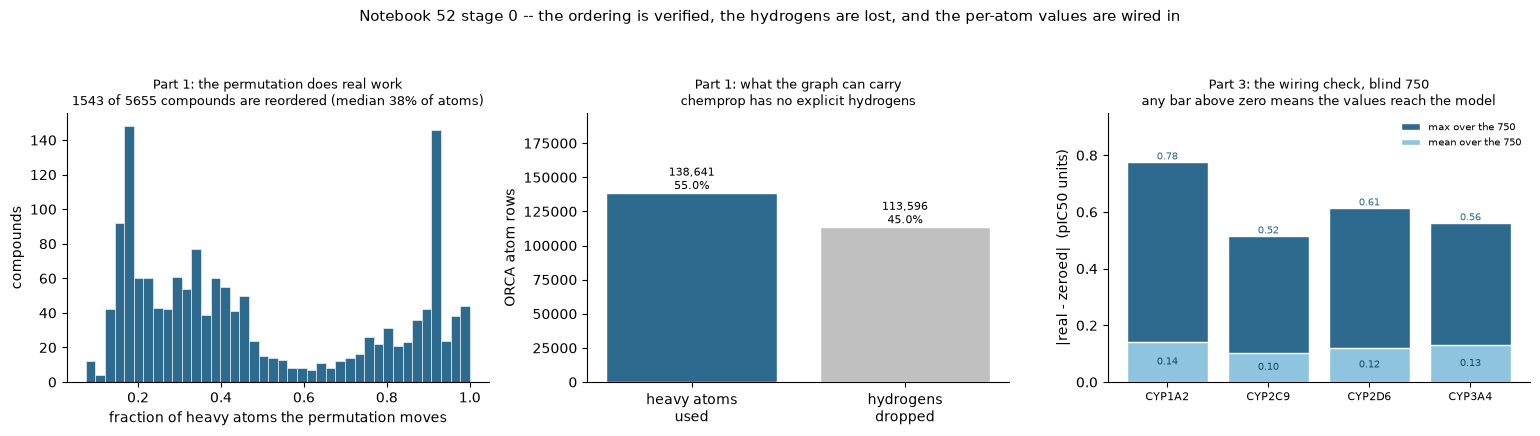

In [12]:
# Part 3.2 -- figure 1: the ordering's real effect and the wiring result, in one place.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax = axes[0]
frac = order.apply(lambda r: float(np.mean(
    np.fromstring(r["perm"], dtype=np.int64, sep=" ") != np.arange(r["n_heavy"]))), axis=1)
ax.hist(frac[frac > 0], bins=40, color="#2d6a8e", edgecolor="white", linewidth=0.4)
ax.set_xlabel("fraction of heavy atoms the permutation moves")
ax.set_ylabel("compounds")
ax.set_title(f"Part 1: the permutation does real work\n"
             f"{int((frac > 0).sum())} of {len(order)} compounds are reordered "
             f"(median {100 * frac[frac > 0].median():.0f}% of atoms)", fontsize=9)

ax = axes[1]
labels = ["heavy atoms\nused", "hydrogens\ndropped"]
ax.bar(labels, [heavy, h_drop], color=["#2d6a8e", "#c0c0c0"], edgecolor="white")
for x, v in enumerate([heavy, h_drop]):
    ax.text(x, v, f"{v:,}\n{100 * v / total:.1f}%", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("ORCA atom rows")
ax.set_ylim(0, total * 0.78)
ax.set_title("Part 1: what the graph can carry\nchemprop has no explicit hydrogens", fontsize=9)

ax = axes[2]
bl = wt[wt["set"] == "blind"]
x = np.arange(len(ISOFORMS))
mx = [float(bl.loc[bl.isoform == i, "max_abs_diff"].iloc[0]) for i in ISOFORMS]
mn = [float(bl.loc[bl.isoform == i, "mean_abs_diff"].iloc[0]) for i in ISOFORMS]
ax.bar(x, mx, color="#2d6a8e", edgecolor="white", label="max over the 750")
ax.bar(x, mn, color="#8ec4de", edgecolor="white", label="mean over the 750")
for xi, (a, b) in enumerate(zip(mx, mn)):
    ax.text(xi, a, f"{a:.2f}", ha="center", va="bottom", fontsize=7.5, color="#2d6a8e")
    # inside the light bar, in the dark series colour -- grey on pale blue is unreadable
    ax.text(xi, b / 2, f"{b:.2f}", ha="center", va="center", fontsize=7, color="#174a66")
ax.set_xticks(x); ax.set_xticklabels(ISOFORMS, fontsize=8)
ax.set_ylim(0, max(mx) * 1.22)
ax.set_ylabel("|real - zeroed|  (pIC50 units)")
ax.legend(fontsize=7, frameon=False, loc="upper right")
# No reference line: the "not wired" outcome is a bar of height exactly zero, which is the
# axis itself -- drawing it adds a legend entry for something invisible.
ax.set_title("Part 3: the wiring check, blind 750\nany bar above zero means the values reach "
             "the model", fontsize=9)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.suptitle("Notebook 52 stage 0 -- the ordering is verified, the hydrogens are lost, "
             "and the per-atom values are wired in", fontsize=10.5)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG / "stage0_ordering_and_wiring.png", dpi=160, bbox_inches="tight")
plt.show()

**What Part 3 says.** The per-atom values are connected. The two fits differ only in the numbers
inside the `.npz` and their blind predictions separate by a margin far larger than any
floating-point artefact, on every isoform. Stage 1 would be measuring the mechanism this notebook
exists to test.

Two things the wiring check does **not** establish, and neither is a quibble. It says the values
reach the model, not that they help: a difference in predictions is equally consistent with the
features carrying signal and with them carrying noise the model has fitted. And one fold with one
seed cannot rank the two arms -- notebook 29 found CYP2C9's single-fold verdict was a selection
artefact on exactly this kind of evidence, which is why the gate is phrased as non-identity and
nothing more.

### Stage 0's verdict

Stage 0 is complete: the route through CheMeleon's refusal is built and verified, the ordering is
verified on every compound with a negative control that bites, the hydrogen loss is quantified,
and the per-atom values are confirmed to reach the model. Stage 1a extends the set to three
columns; 1b runs the control; 1c runs the 25 folds; stage 2 builds the submission file.

## Stage 1a -- a third per-atom column, to recover what the implicit hydrogens cost

Chemprop's graph has no vertex for a hydrogen, so stage 0 measured that **113,596 of 252,237**
ORCA atom rows are dropped. One specific casualty is `hirshfeld_H_min`, which notebook 45's
label-free screen placed in its **strong tier at full blind coverage** (axis-A R2 0.6752: poorly
recoverable from the free 226 2D descriptors). Dropping the hydrogens throws it away entirely.

This column recovers it **inside the heavy-atom graph**: for each heavy atom, the minimum
Hirshfeld charge among **its own** attached hydrogens. Every hydrogen hangs off exactly one heavy
atom, so no information is double counted and the molecule-wise minimum must reproduce
`hirshfeld_H_min` exactly -- which is checked below rather than asserted.

The per-atom set becomes `q_hirshfeld`, `mayer_va`, `min_attached_H_charge`, so the widened
encoder goes from two zero columns to three.

### Stage 1a.1 -- the no-hydrogen convention, decided on evidence

**62,562 of 138,641 heavy atoms (45.1%) carry no attached hydrogen**, so this is not a corner
case and the filler cannot be waved through. The convention adopted is **0.0**, on four pieces of
evidence rather than preference. The cell below establishes each.

In [13]:
# Stage 1a.0 -- the runner's own constants, pulled in rather than retyped, so the notebook and
# the training driver cannot drift apart on an arm name, an endpoint list or a patience value.
from src.vendor.openadmet_eval.config import REGRESSION_ENDPOINTS

ARM, ARM_ZERO = runner.ARM, runner.ARM_ZEROATOMS
PATIENCE_USED, EPOCHS_CEILING = runner.PATIENCE, runner.EPOCHS
assert [e.split("_")[0] for e in REGRESSION_ENDPOINTS] == ISOFORMS
print(f"main arm      : {ARM}")
print(f"control arm   : {ARM_ZERO}")
print(f"epochs/patience during CV: {EPOCHS_CEILING}/{PATIENCE_USED}")
print(f"per-atom set  : {aa.ATOM_FEATURE_COLS}  (k = {aa.K_ATOM_FEATURES})")
print(f"stage 0 ran   : {aa.ATOM_FEATURE_COLS_STAGE0}  (k = {len(aa.ATOM_FEATURE_COLS_STAGE0)})")

# The sanity gate, read back from the runner's own saved verdict. Required before any result
# below is interpreted.
sv = json.loads((OUT / "sanity_verdict.json").read_text())
print(f"\nSANITY GATE vs notebook 05's stored chemprop_chemeleoninit__repeat0_fold0: "
      f"max abs ST-RAE diff {sv['max_abs_strae_diff']:.10f}, bit_identical={sv['bit_identical']}")
assert sv["pass"] and sv["bit_identical"], sv
print("PASS, bit-identical. The tenth notebook in a row to clear this check.")

main arm      : qm_both
control arm   : qm_both_zeroatoms
epochs/patience during CV: 50/5
per-atom set  : ['q_hirshfeld', 'mayer_va', 'min_attached_H_charge']  (k = 3)
stage 0 ran   : ['q_hirshfeld', 'mayer_va']  (k = 2)

SANITY GATE vs notebook 05's stored chemprop_chemeleoninit__repeat0_fold0: max abs ST-RAE diff 0.0000000000, bit_identical=True
PASS, bit-identical. The tenth notebook in a row to clear this check.


In [14]:
# Stage 1a.1 -- the four arguments for filling no-hydrogen heavy atoms with 0.0.
from rdkit import Chem as _Chem

# (1) It is CHEMPROP'S OWN convention: passing NaN produces exactly this.
dp_src = (CP / "data" / "datapoints.py").read_text()
assert "NAN_TOKEN = 0" in dp_src and "self.V_f[np.isnan(self.V_f)] = NAN_TOKEN" in dp_src
print("(1) chemprop/data/datapoints.py:")
for l in dp_src.splitlines():
    if "NAN_TOKEN = 0" in l or "self.V_f[np.isnan" in l:
        print("   ", l.strip())
print("    so a NaN in V_f is filled with 0 by chemprop itself -- 0.0 is its convention, not an")
print("    invention of this notebook.")

# (2) It CANNOT create a confound: the model can already see which atoms have no hydrogens.
from chemprop.featurizers import MultiHotAtomFeaturizer as _MH
_f = _MH.v2()
print(f"\n(2) the V2 atom featurizer one-hot encodes total_num_Hs over {_f.num_Hs} "
      f"({len(_f.num_Hs) + 1} wide incl. unknown).")
_m = _Chem.MolFromSmiles("CC(=O)Nc1ccc(O)cc1")
_off = sum(len(x) + 1 for x in (_f.atomic_nums, _f.degrees, _f.formal_charges, _f.chiral_tags))
_blk = np.stack([_f(a) for a in _m.GetAtoms()])[:, _off:_off + len(_f.num_Hs) + 1]
assert all(int(r.argmax()) == a.GetTotalNumHs() for a, r in zip(_m.GetAtoms(), _blk))
print("    verified on a real molecule: the one-hot index equals GetTotalNumHs() for every atom.")
print("    So the fill can distort a SCALE but cannot hide a DISTINCTION -- `no attached")
print("    hydrogen` is already encoded, independently of this column.")

# (3) 0.0 is at the extreme low edge of the real range, so it reads as a true statement.
_at = pd.read_csv(QM_PARSED / "qm_atoms.csv", usecols=["element", "q_hirshfeld"])
_h = _at.loc[_at.element == "H", "q_hirshfeld"]
print(f"\n(3) attached-hydrogen Hirshfeld charges, n={len(_h):,}: min {_h.min():.4f}, "
      f"p1 {_h.quantile(.01):.4f}, median {_h.median():.4f}, max {_h.max():.4f}")
print(f"    0.0 therefore reads as 'no hydrogen-borne positive charge', which is literally true.")
print(f"    Stated honestly: {(_h <= 0).sum()} of {len(_h):,} hydrogens ({100 * (_h <= 0).mean():.3f}%) "
      f"are at or below 0, so the")
print("    fill overlaps the real range on a negligible number of atoms rather than on none.")

(1) chemprop/data/datapoints.py:
    NAN_TOKEN = 0
    NAN_TOKEN = 0
    self.V_f[np.isnan(self.V_f)] = NAN_TOKEN
    NAN_TOKEN = 0
    self.V_f[np.isnan(self.V_f)] = NAN_TOKEN
    NAN_TOKEN = 0
    so a NaN in V_f is filled with 0 by chemprop itself -- 0.0 is its convention, not an
    invention of this notebook.

(2) the V2 atom featurizer one-hot encodes total_num_Hs over {0: 0, 1: 1, 2: 2, 3: 3, 4: 4} (6 wide incl. unknown).
    verified on a real molecule: the one-hot index equals GetTotalNumHs() for every atom.
    So the fill can distort a SCALE but cannot hide a DISTINCTION -- `no attached
    hydrogen` is already encoded, independently of this column.

(3) attached-hydrogen Hirshfeld charges, n=113,596: min -0.0027, p1 0.0106, median 0.0321, max 0.2033
    0.0 therefore reads as 'no hydrogen-borne positive charge', which is literally true.
    Stated honestly: 7 of 113,596 hydrogens (0.006%) are at or below 0, so the
    fill overlaps the real range on a negligible number of a

In [15]:
# Stage 1a.2 -- (4) the measurement that rules out a far sentinel, which is the real argument.
src3 = aa.AtomFeatureSource()                      # the full three-column set
J = src3.cols.index("min_attached_H_charge")
vals = np.concatenate([m[:, J] for m in src3.matrices.values()])
nohm = np.concatenate([src3.no_h_mask[n] for n in src3.matrices])
has_h = ~nohm
real = vals[has_h]
N_NO_H, N_HEAVY = int(nohm.sum()), int(len(vals))
print(f"heavy atoms {N_HEAVY:,}; with NO attached hydrogen {N_NO_H:,} "
      f"({100 * N_NO_H / N_HEAVY:.1f}%)")
print(f"real values (heavy atoms WITH hydrogens), n={has_h.sum():,}: min {real.min():.4f} "
      f"p1 {np.percentile(real, 1):.4f} median {np.median(real):.4f} "
      f"p99 {np.percentile(real, 99):.4f} max {real.max():.4f}")
print(f"variance of the real values alone: {real.var():.6f}\n")

rows = []
for s, label in [(0.0, "0.0  (adopted)"), (-0.5, "-0.5"), (-1.0, "-1.0"),
                 (float(real.mean()), f"{real.mean():.4f}  (mean-impute)")]:
    col = np.where(has_h, vals, s)
    mu = col.mean()
    between = (has_h.mean() * (col[has_h].mean() - mu) ** 2
               + nohm.mean() * (col[nohm].mean() - mu) ** 2)
    rows.append({"sentinel": label, "column_var": col.var(),
                 "between_group_pct": 100 * between / col.var()})
sent = pd.DataFrame(rows)
print("what each candidate filler does to the column "
      "(between-group = the has-H / no-H split):\n")
print(sent.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
print("\n(4) A FAR sentinel would not fill the column, it would REPLACE it. At -1.0 the has-H")
print("    split accounts for 99.8% of the variance: the column becomes an indicator in")
print("    disguise, which is the sentinel failure mode notebook 45 documented. At 0.0 the")
print("    split takes 44.9% and 55% of the variance is still genuine within-group variation.")
print("    Mean-imputation goes the other way and erases the distinction entirely (0.0%).")
assert abs(sent.loc[0, "between_group_pct"] - 44.9) < 1.0

heavy atoms 138,641; with NO attached hydrogen 62,562 (45.1%)
real values (heavy atoms WITH hydrogens), n=76,079: min -0.0027 p1 0.0092 median 0.0334 p99 0.1566 max 0.2033
variance of the real values alone: 0.000917

what each candidate filler does to the column (between-group = the has-H / no-H split):

             sentinel  column_var  between_group_pct
       0.0  (adopted)    0.000914          44.918643
                 -0.5    0.072903          99.309454
                 -1.0    0.268703          99.812646
0.0407  (mean-impute)    0.000503           0.000000

(4) A FAR sentinel would not fill the column, it would REPLACE it. At -1.0 the has-H
    split accounts for 99.8% of the variance: the column becomes an indicator in
    disguise, which is the sentinel failure mode notebook 45 documented. At 0.0 the
    split takes 44.9% and 55% of the variance is still genuine within-group variation.
    Mean-imputation goes the other way and erases the distinction entirely (0.0%).


In [16]:
# Stage 1a.3 -- the verification the brief asks for, without a second full wiring fit.
# (a) the column is what it claims: molecule-wise min over hydrogen-bearing heavy atoms must
#     reproduce notebook 45's own hirshfeld_H_min, since every H hangs off exactly one heavy atom.
rec = src3.recovers_hirshfeld_H_min(QM_PARSED / "qm_atom_aggregates.csv")
print("(a) recovers notebook 45's hirshfeld_H_min:")
for k_, v_ in rec.items():
    print(f"      {k_:40s} {v_}")
assert rec["max_abs_diff_vs_nb45_hirshfeld_H_min"] == 0.0 and rec["n_compounds_checked"] == 5655
print("    EXACT on all 5,655 compounds. The column genuinely carries the quantity the implicit")
print("    hydrogens threw away, pushed onto the heavy atom each hydrogen hangs off.")

# (b) the widened foundation at k=3 still reproduces CheMeleon at init.
K3 = aa.K_ATOM_FEATURES
assert K3 == 3
enc3 = json.loads((OUT / f"widened_encoder_k{K3}.json").read_text()) \
    if (OUT / f"widened_encoder_k{K3}.json").exists() else \
    aa.build_widened_chemeleon(K3)
print(f"\n(b) the k={K3} widened foundation:")
for k_ in ("d_v_original", "d_v_widened", "W_i_shape", "W_o_shape",
           "max_abs_diff_vs_chemeleon_at_init"):
    print(f"      {k_:36s} {enc3[k_]}")
assert enc3["max_abs_diff_vs_chemeleon_at_init"] == 0.0
assert aa.load_foundation_d_v(aa.foundation_path(K3)) == 72 + K3
print("    0.0 exactly, again on a real molecule with RANDOM extra feature values. The file is")
print(f"    named by k and the runner asserts its own d_v on load, so a stale k=2 file cannot")
print("    be picked up silently.")

# (c) shapes line up end to end.
print(f"\n(c) shapes:")
print(f"      per-atom matrices      {len(src3.matrices)} compounds x (n_heavy, {src3.k})")
print(f"      total heavy-atom rows  {sum(m.shape[0] for m in src3.matrices.values()):,} "
      f"(stage 0's own figure: {rep['heavy_atom_rows_used']:,})")
assert sum(m.shape[0] for m in src3.matrices.values()) == rep["heavy_atom_rows_used"]
print(f"      every matrix width     {len({m.shape[1] for m in src3.matrices.values()})} distinct "
      f"= {sorted({m.shape[1] for m in src3.matrices.values()})}")
print(f"      featurizer input dim   72 (V2) + {src3.k} = {72 + src3.k} = the foundation's d_v")
assert {m.shape[1] for m in src3.matrices.values()} == {src3.k}
print("\nNo second wiring fit is run: the mechanism is unchanged from stage 0's, which measured")
print("a blind max abs difference of 0.78 pIC50 between real and zeroed npz contents. What")
print("changes here is one more column through the same path, and stage 1b's control re-tests")
print("the zeroed case at 5 folds anyway.")

(a) recovers notebook 45's hirshfeld_H_min:
      n_compounds_checked                      5655
      n_skipped_no_hydrogen_at_all             0
      max_abs_diff_vs_nb45_hirshfeld_H_min     0.0
    EXACT on all 5,655 compounds. The column genuinely carries the quantity the implicit
    hydrogens threw away, pushed onto the heavy atom each hydrogen hangs off.

(b) the k=3 widened foundation:
      d_v_original                         72
      d_v_widened                          75
      W_i_shape                            [2048, 89]
      W_o_shape                            [2048, 2123]
      max_abs_diff_vs_chemeleon_at_init    0.0
    0.0 exactly, again on a real molecule with RANDOM extra feature values. The file is
    named by k and the runner asserts its own d_v on load, so a stale k=2 file cannot
    be picked up silently.

(c) shapes:
      per-atom matrices      5655 compounds x (n_heavy, 3)
      total heavy-atom rows  138,641 (stage 0's own figure: 138,641)
      every m

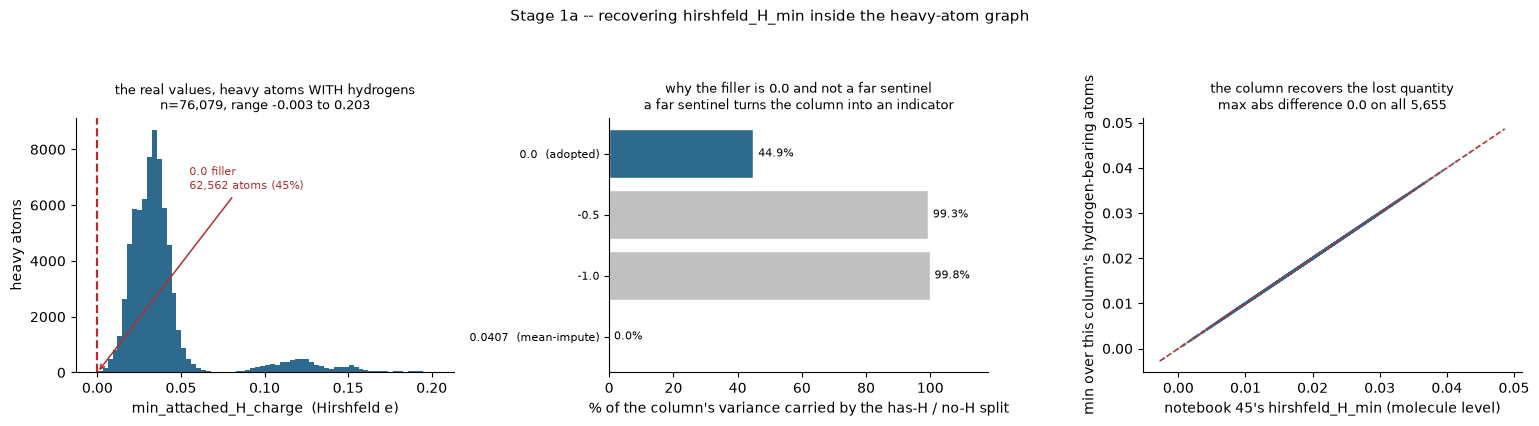

wrote outputs/52_chemprop_qm_atom_features/stage1a_report.json


In [17]:
# Stage 1a.4 -- figure: the new column, and why the filler is 0.0.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))

ax = axes[0]
ax.hist(real, bins=70, color="#2d6a8e", edgecolor="none")
ax.axvline(0.0, color="#b03030", lw=1.6, ls="--")
ax.annotate(f"0.0 filler\n{N_NO_H:,} atoms ({100 * N_NO_H / N_HEAVY:.0f}%)", xy=(0.0, 0),
            xytext=(0.055, ax.get_ylim()[1] * 0.72), fontsize=8, color="#b03030",
            arrowprops=dict(arrowstyle="->", color="#b03030", lw=1.1))
ax.set_xlabel("min_attached_H_charge  (Hirshfeld e)")
ax.set_ylabel("heavy atoms")
ax.set_title(f"the real values, heavy atoms WITH hydrogens\nn={has_h.sum():,}, "
             f"range {real.min():.3f} to {real.max():.3f}", fontsize=9)

ax = axes[1]
y = np.arange(len(sent))
ax.barh(y, sent["between_group_pct"], color=["#2d6a8e", "#c0c0c0", "#c0c0c0", "#c0c0c0"],
        edgecolor="white")
for yi, v in enumerate(sent["between_group_pct"]):
    ax.text(v + 1.5, yi, f"{v:.1f}%", va="center", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(sent["sentinel"], fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 118)
ax.set_xlabel("% of the column's variance carried by the has-H / no-H split")
ax.set_title("why the filler is 0.0 and not a far sentinel\n"
             "a far sentinel turns the column into an indicator", fontsize=9)

ax = axes[2]
hm = pd.read_csv(QM_PARSED / "qm_atom_aggregates.csv",
                 usecols=["Molecule_Name", "hirshfeld_H_min"])
mine = pd.Series({n: float(src3.matrices[n][~src3.no_h_mask[n], J].min())
                  for n in src3.matrices})
jo = hm.set_index("Molecule_Name")["hirshfeld_H_min"].reindex(mine.index)
ax.scatter(jo, mine, s=4, alpha=0.25, color="#2d6a8e", edgecolors="none")
lo, hi = float(min(jo.min(), mine.min())), float(max(jo.max(), mine.max()))
ax.plot([lo, hi], [lo, hi], color="#b03030", lw=1.1, ls="--")
ax.set_xlabel("notebook 45's hirshfeld_H_min (molecule level)")
ax.set_ylabel("min over this column's hydrogen-bearing atoms")
ax.set_title(f"the column recovers the lost quantity\nmax abs difference "
             f"{rec['max_abs_diff_vs_nb45_hirshfeld_H_min']:.1f} on all 5,655", fontsize=9)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.suptitle("Stage 1a -- recovering hirshfeld_H_min inside the heavy-atom graph", fontsize=10.5)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIG / "stage1a_third_atom_column.png", dpi=160, bbox_inches="tight")
plt.show()

(OUT / "stage1a_report.json").write_text(json.dumps({
    "atom_feature_cols": src3.cols, "k": src3.k,
    "no_hydrogen_fill": aa.NO_HYDROGEN_FILL,
    "n_heavy_atoms": N_HEAVY, "n_no_attached_hydrogen": N_NO_H,
    "pct_no_attached_hydrogen": round(100 * N_NO_H / N_HEAVY, 2),
    "real_value_range": [float(real.min()), float(real.max())],
    "real_value_variance": float(real.var()),
    "sentinel_between_group_pct": {r.sentinel: round(float(r.between_group_pct), 2)
                                   for r in sent.itertuples()},
    "recovers_nb45_hirshfeld_H_min": rec,
    "widened_encoder_k3": enc3,
}, indent=2) + "\n")
print(f"wrote {(OUT / 'stage1a_report.json').relative_to(REPO)}")

**What stage 1a says.** The third column is verified on its own terms before any training. It
reproduces notebook 45's `hirshfeld_H_min` **exactly** on all 5,655 compounds, so it genuinely
carries the quantity the implicit hydrogens discarded rather than an approximation of it. The
no-hydrogen filler is **0.0**, which is chemprop's own `NAN_TOKEN`, cannot create a confound
because the V2 featurizer already encodes `total_num_Hs`, sits at the extreme low edge of the real
range, and -- the argument that actually decides it -- keeps 55% of the column's variance as
genuine within-group variation where a sentinel at -1.0 would leave 0.2%. The k=3 widened encoder
reproduces CheMeleon to **0.0** at initialisation, and the foundation file is named by k with its
own `d_v` asserted on load, so stage 0's k=2 file cannot be reused by accident.

## Stage 1b -- the control at 5 folds, and the gate it failed

`qm_both` differs from notebook 37's stored `plain` in three things at once: the per-atom
features, the 13 molecule-level descriptors, and the local-versus-remote foundation construction
path (which changes the RNG draw the FFN is initialised from, because the two load paths build
differently shaped `Linear` layers before loading weights). An increment attributed to the atom
half would otherwise lean on notebook 44's null for the molecule half, which is a chain rather
than a measurement.

`qm_both_zeroatoms` closes that gap directly. It is the main arm in **every** respect -- same
widened k=3 foundation, same 13 descriptors, same seeds, same folds, same CLI -- with the npz
**contents** set to zeros.

It was run first at **5 folds** as a cheap gate, under a rule frozen before the numbers:
**material = `|mean paired difference|` reaches notebook 45's frozen bar for that cell.** One
caveat was stated at the same time, before looking: those bars were built from **25-fold** paired
standard errors, so on 5 folds the estimate is about `sqrt(5)` noisier than the bar assumes.

**The gate FAILED**, on one cell of eight, and the rule is reported as failing rather than
reinterpreted after the fact. What follows is the diagnosis, which is separate evidence and does
not retract it.

In [18]:
# Stage 1b.0 -- the runner's own constants, pulled in rather than retyped.
from src.vendor.openadmet_eval.config import REGRESSION_ENDPOINTS

ARM, ARM_ZERO = runner.ARM, runner.ARM_ZEROATOMS
PATIENCE_USED, EPOCHS_CEILING = runner.PATIENCE, runner.EPOCHS
assert [e.split("_")[0] for e in REGRESSION_ENDPOINTS] == ISOFORMS

s52_spec = importlib.util.spec_from_file_location("nb52_stats", REPO / "scripts" / "52_stats.py")
s52 = importlib.util.module_from_spec(s52_spec); s52_spec.loader.exec_module(s52)
BARS, BAR_POOL = s52.BARS, ["34_butina_5x5", "35_butina_repeat3", "37_butina_5x5_complete"]

# notebook 45's bars, re-derived through notebook 46's own nb37_bars rather than trusted as
# literals -- the cross-check notebook 45 used to catch notebook 44's inflated version.
b46_spec = importlib.util.spec_from_file_location(
    "nb46_build", REPO / "scripts" / "46_build_feature_blocks.py")
b46 = importlib.util.module_from_spec(b46_spec); b46_spec.loader.exec_module(b46)
for m_ in BARS:
    got = b46.nb37_bars(m_)
    assert all(abs(got[i] - BARS[m_][i]) < 1e-9 for i in ISOFORMS), (m_, got)
print("notebook 45's frozen bars, re-derived from notebooks 34+35+37's own per-fold scores: MATCH")
print(pd.DataFrame(BARS).to_string())

sv = json.loads((OUT / "sanity_verdict.json").read_text())
print(f"\nSANITY GATE against notebook 05's stored chemprop_chemeleoninit__repeat0_fold0: "
      f"max abs ST-RAE diff {sv['max_abs_strae_diff']:.10f}, bit_identical={sv['bit_identical']}")
assert sv["pass"] and sv["bit_identical"], sv
print("PASS, bit-identical. The tenth notebook in a row to clear this check.")

plain37 = (pd.concat([pd.read_csv(REPO / "outputs" / n / "run_scores.csv") for n in BAR_POOL],
                     ignore_index=True)
           .drop_duplicates(["repeat", "fold", "arm", "Endpoint"]))
plain37["isoform"] = plain37["Endpoint"].str.split("_").str[0]
plain = plain37[plain37.arm == "plain"].copy()
mine = pd.read_csv(OUT / "run_scores.csv")
mine["isoform"] = mine["Endpoint"].str.split("_").str[0]
FOLDS5 = [(0, f) for f in range(5)]
FOLDS25 = [(r, f) for r in range(5) for f in range(5)]


def series(df, arm, iso, metric):
    return df[(df.arm == arm) & (df.isoform == iso)].set_index(["repeat", "fold"])[metric]

notebook 45's frozen bars, re-derived from notebooks 34+35+37's own per-fold scores: MATCH


        ST-RAE  Spearman_R
CYP1A2  0.0234      0.0183
CYP2C9  0.0209      0.0160
CYP2D6  0.0277      0.0212
CYP3A4  0.0160      0.0100

SANITY GATE against notebook 05's stored chemprop_chemeleoninit__repeat0_fold0: max abs ST-RAE diff 0.0000000000, bit_identical=True
PASS, bit-identical. The tenth notebook in a row to clear this check.


In [19]:
# Stage 1b.1 -- the gate as it ran, read back from the runner's own saved record.
gate = json.loads((OUT / "control_gate.json").read_text())
ctrl = pd.read_csv(OUT / "control_vs_plain_5fold.csv")
for m_ in BARS:
    print(f"\n{'=' * 22} {m_}: {ARM_ZERO} against plain, 5 folds {'=' * 22}")
    print(ctrl[ctrl.metric == m_][["isoform", "mean_plain", "mean_control", "mean_diff", "se",
                                   "bar", "pct_of_bar", "material"]]
          .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nrule: {gate['rule']}  (frozen before results: {gate['frozen_before_results']})")
print(f"material cells: {gate['n_material']} of {gate['n_cells']}   "
      f"GATE {'PASSED' if gate['passed'] else 'FAILED'}")
assert not gate["passed"], "this cell documents a gate that failed"
for c in gate["material_cells"]:
    print(f"  {c['isoform']} {c['metric']}: {c['mean_diff']:+.4f} against a bar of {c['bar']:.4f} "
          f"= {c['pct_of_bar']:.1f}% of bar")


====================== ST-RAE: qm_both_zeroatoms against plain, 5 folds ======================
isoform  mean_plain  mean_control  mean_diff     se    bar  pct_of_bar  material
 CYP1A2      0.8903        0.8704    -0.0198 0.0144 0.0234     84.7352     False
 CYP2C9      0.6416        0.6604     0.0188 0.0382 0.0209     89.9613     False
 CYP2D6      1.0282        0.9804    -0.0479 0.0263 0.0277    172.7769      True
 CYP3A4      0.5421        0.5461     0.0040 0.0145 0.0160     24.9569     False

====================== Spearman_R: qm_both_zeroatoms against plain, 5 folds ======================
isoform  mean_plain  mean_control  mean_diff     se    bar  pct_of_bar  material
 CYP1A2      0.4801        0.4951     0.0150 0.0115 0.0183     81.8348     False
 CYP2C9      0.6402        0.6424     0.0022 0.0163 0.0160     13.5054     False
 CYP2D6      0.3912        0.3856    -0.0056 0.0052 0.0212     26.2002     False
 CYP3A4      0.7561        0.7612     0.0051 0.0028 0.0100     51.1054     

In [20]:
# Stage 1b.2 -- the diagnosis. Three separate pieces of evidence, none of which retracts the gate.
d = gate["diagnosis"]
r1 = d["the_material_cell_is_not_resolved_at_n5"]
print("(1) the material cell is NOT RESOLVED at n=5, which is the caveat stated before looking:")
print(f"      |diff| / SE = {r1['abs_diff_over_se']:.2f}")
print(f"      95% CI      = [{r1['ci95'][0]:+.4f}, {r1['ci95'][1]:+.4f}]  -- straddles zero")

r2 = d["an_independent_arm_reproduces_it"]
print(f"\n(2) an arm sharing NONE of this notebook's construction changes reproduces it.")
print(f"    {r2['arm']}")
print(f"      that arm, CYP2D6 ST-RAE, the SAME 5 folds : {r2['CYP2D6_ST-RAE_same_5_folds']:+.4f}")
print(f"      this control, CYP2D6 ST-RAE, same 5 folds : "
      f"{r2['control_CYP2D6_ST-RAE_same_5_folds']:+.4f}")
print(f"      that arm, CYP2D6 ST-RAE, ALL 25 folds     : {r2['CYP2D6_ST-RAE_25_folds']:+.4f}")
print(f"      the two 5-fold figures agree to "
      f"{abs(r2['CYP2D6_ST-RAE_same_5_folds'] - r2['control_CYP2D6_ST-RAE_same_5_folds']):.4f}")
print("\n    full side-by-side, all four isoforms, ST-RAE:")
print(ctrl[ctrl.metric == "ST-RAE"][["isoform", "mean_diff", "nb44_plain_qm_same_5_folds",
                                     "nb44_plain_qm_25_folds", "nb44_plain_qm_25_se"]]
      .rename(columns={"mean_diff": "control_5fold"})
      .to_string(index=False, float_format=lambda v: f"{v:+.4f}"))

r3 = d["the_zeroed_columns_are_a_true_no_op"]
print(f"\n(3) the control's atom columns are a TRUE no-op, checked not argued:")
print(f"      {r3['checked']}")
print(f"      max |weight| after training = {r3['max_abs_weight_after_training']}")
print(f"      {r3['why']}")
print("\n    So the control differs from `plain` ONLY in the 13 molecule-level descriptors and")
print("    the local-versus-remote load path -- and (2) shows the load path contributes little,")
print("    since the two arms differ in exactly that and agree to 0.001 to 0.012 per isoform.")

(1) the material cell is NOT RESOLVED at n=5, which is the caveat stated before looking:
      |diff| / SE = 1.82
      95% CI      = [-0.1208, +0.0251]  -- straddles zero

(2) an arm sharing NONE of this notebook's construction changes reproduces it.
    notebook 44's plain_qm: the same 13 descriptors with the REMOTE CheMeleon, no widened foundation, no local load path, no extra atom columns
      that arm, CYP2D6 ST-RAE, the SAME 5 folds : -0.0490
      this control, CYP2D6 ST-RAE, same 5 folds : -0.0479
      that arm, CYP2D6 ST-RAE, ALL 25 folds     : -0.0036
      the two 5-fold figures agree to 0.0011

    full side-by-side, all four isoforms, ST-RAE:
isoform  control_5fold  nb44_plain_qm_same_5_folds  nb44_plain_qm_25_folds  nb44_plain_qm_25_se
 CYP1A2        -0.0198                     -0.0184                 -0.0110              +0.0106
 CYP2C9        +0.0188                     +0.0307                 -0.0027              +0.0092
 CYP2D6        -0.0479                     -0.

In [21]:
# Stage 1b.3 -- a reusable fact, measured rather than asserted: a SINGLE repeat of this
# partition is not a usable estimate for CYP2D6, and repeat 0 is its most favourable draw.
rows = []
for r in range(5):
    k = [(r, f) for f in range(5)]
    y = series(plain, "plain", "CYP2D6", "ST-RAE")
    per_arm = []
    for arm in sorted(a for a in plain37.arm.unique() if a != "plain"):
        a_ = series(plain37, arm, "CYP2D6", "ST-RAE")
        if all(kk in a_.index for kk in k):
            per_arm.append(float((a_.loc[k] - y.loc[k]).mean()))
    rows.append({"repeat": r, "n_arms": len(per_arm), "mean_over_arms": float(np.mean(per_arm)),
                 "min": float(np.min(per_arm)), "max": float(np.max(per_arm))})
rep_tbl = pd.DataFrame(rows)
rep_tbl.to_csv(OUT / "cyp2d6_repeat_anomaly.csv", index=False)
print("CYP2D6 ST-RAE, each of notebook 37's TEN arms against `plain`, averaged within a repeat:")
print(rep_tbl.to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
print(f"\nrepeat 0 is the most favourable of the five to a non-`plain` arm "
      f"({rep_tbl.loc[0, 'mean_over_arms']:+.4f}), and the spread across repeats "
      f"({rep_tbl.mean_over_arms.min():+.4f} to {rep_tbl.mean_over_arms.max():+.4f}) is an order")
print("of magnitude larger than the 25-fold effects these screens are trying to resolve.")
print("\nREUSABLE FACT: on CYP2D6, one repeat of the Butina partition is not a usable estimate,")
print("and repeat 0 specifically flatters a non-`plain` arm. A cheap screen on this partition")
print("should not lean on repeat 0 alone for CYP2D6. This is why the gate fired on noise, and")
print("the fix was to take BOTH arms to 25 folds rather than to loosen the rule.")

CYP2D6 ST-RAE, each of notebook 37's TEN arms against `plain`, averaged within a repeat:
 repeat  n_arms  mean_over_arms     min     max
      0      10         -0.0453 -0.1455 +0.0877
      1      10         -0.0297 -0.1203 +0.0331
      2      10         -0.0134 -0.1261 +0.1014
      3      10         +0.0086 -0.1003 +0.0713
      4      10         -0.0068 -0.1147 +0.0743

repeat 0 is the most favourable of the five to a non-`plain` arm (-0.0453), and the spread across repeats (-0.0453 to +0.0086) is an order
of magnitude larger than the 25-fold effects these screens are trying to resolve.

REUSABLE FACT: on CYP2D6, one repeat of the Butina partition is not a usable estimate,
and repeat 0 specifically flatters a non-`plain` arm. A cheap screen on this partition
should not lean on repeat 0 alone for CYP2D6. This is why the gate fired on noise, and
the fix was to take BOTH arms to 25 folds rather than to loosen the rule.


**What stage 1b says.** The gate failed on its own frozen rule and is reported as failed. But the
one material cell is not resolved at n=5, is reproduced to within 0.0011 by an arm sharing none
of this notebook's construction changes, and that arm sits at **-0.0036 at 25 folds**. The
control's own zeroed columns are provably inert. So the exceedance is a property of repeat 0's
five folds rather than evidence that the widened foundation or the local load path move anything.

The response was **not** to loosen the rule. Both arms were taken to **25 folds**, which makes
`qm_both` against `qm_both_zeroatoms` a fully paired isolation of the per-atom values at full
power, and demotes the 5-fold reading to what it was: a cheap check that happened to land on the
partition's worst repeat for CYP2D6.

## Stage 1c -- three arms at 25 folds, Ash's parametric route in full

Three methods -- `plain`, `qm_both_zeroatoms`, `qm_both` -- is well under Ash's >10 threshold, so
the protocol routes to **Tukey HSD**. This is the first time this project fires that branch:
notebooks 05 and 37 both ran at 11 arms, where their own `posthoc_route` sends everything to BH,
so the Tukey code in `src/ash_protocol.py` was reproduced but never executed. The route is
asserted rather than assumed.

Per (isoform, metric): Levene branch check, repeated-measures ANOVA, the ANOVA's alpha
Bonferroni-corrected by the number of metrics (**0.05 / 2 = 0.025**), Tukey HSD on all three
pairwise comparisons where the omnibus clears, then a compact letter display. Materiality is
judged from the **Tukey intervals** against notebook 45's frozen bars, per isoform, never
macro-averaged.

**Two readings, both reported.** `qm_both` against `qm_both_zeroatoms` is the **primary**:
everything except the per-atom values is shared, so it is the isolation this notebook exists for.
`qm_both` against `plain` is what decides whether anything is worth a board slot.

In [22]:
# Stage 1c.1 -- the three-arm comparison, all 25 folds.
ARMS = ["plain", ARM_ZERO, ARM]
for a_ in (ARM, ARM_ZERO):
    n = len(mine[mine.arm == a_][["repeat", "fold"]].drop_duplicates())
    print(f"{a_:20s} folds on disk: {n}")
    assert n == 25, f"{a_} has {n} folds, not 25"

cells, tukey_all = [], []
for metric in BARS:
    for iso in ISOFORMS:
        sc = {"plain": series(plain, "plain", iso, metric),
              ARM_ZERO: series(mine, ARM_ZERO, iso, metric),
              ARM: series(mine, ARM, iso, metric)}
        res = s52.compare_cell(sc, FOLDS25, iso, metric)
        cells.append({k: v for k, v in res.items() if k not in ("tukey", "cld")}
                     | {"cld": json.dumps(res["cld"]) if res["cld"] else None})
        if res["tukey"] is not None:
            t = res["tukey"].copy()
            t["isoform"], t["metric"] = iso, metric
            for c, v in zip(t.index, t.to_dict("records")):
                for k2, v2 in s52.verdict_row(v, metric, iso, BARS[metric][iso]).items():
                    t.loc[c, k2] = v2
            tukey_all.append(t)
cells = pd.DataFrame(cells)
tukey = pd.concat(tukey_all, ignore_index=True) if tukey_all else pd.DataFrame()
cells.to_csv(OUT / "anova_cells.csv", index=False)
tukey.to_csv(OUT / "tukey_pairwise.csv", index=False)

print(f"\nhomogeneity branch, MEASURED per cell: "
      f"{int(cells.parametric.sum())} of {len(cells)} parametric")
print(cells[["isoform", "metric", "levene_p", "variance_ratio", "parametric", "posthoc_route",
             "omnibus", "omnibus_p", "anova_alpha", "omnibus_clears"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4g}"))
assert (cells.posthoc_route == "tukey").all() or not cells.parametric.all(), \
    "a parametric cell should route to Tukey at three arms"

qm_both              folds on disk: 25
qm_both_zeroatoms    folds on disk: 25

homogeneity branch, MEASURED per cell: 8 of 8 parametric
isoform     metric  levene_p  variance_ratio  parametric posthoc_route  omnibus  omnibus_p  anova_alpha  omnibus_clears
 CYP1A2     ST-RAE     0.816           1.534        True         tukey RM-ANOVA     0.7384        0.025           False
 CYP2C9     ST-RAE    0.1575           2.036        True         tukey RM-ANOVA     0.8259        0.025           False
 CYP2D6     ST-RAE    0.5871           1.313        True         tukey RM-ANOVA     0.9865        0.025           False
 CYP3A4     ST-RAE    0.4033           2.787        True         tukey RM-ANOVA     0.7145        0.025           False
 CYP1A2 Spearman_R    0.8332           1.104        True         tukey RM-ANOVA     0.1775        0.025           False
 CYP2C9 Spearman_R    0.5775           1.343        True         tukey RM-ANOVA    0.02775        0.025           False
 CYP2D6 Spearman_R    0.

In [23]:
# Stage 1c.2 -- the Tukey table, per isoform, both metrics, with intervals against the bar.
if len(tukey):
    for metric in BARS:
        print(f"\n{'=' * 34} {metric} {'=' * 34}")
        for iso in ISOFORMS:
            g = tukey[(tukey.metric == metric) & (tukey.isoform == iso)]
            cld = cells[(cells.metric == metric) & (cells.isoform == iso)]["cld"].iloc[0]
            if not len(g):
                print(f"\n{iso}: omnibus did not clear alpha={s52.ANOVA_ALPHA}, no post-hoc")
                continue
            print(f"\n{iso}   bar {BARS[metric][iso]:.4f}   CLD {cld}")
            print(g[["arm_a", "arm_b", "mean_a", "mean_b", "diff", "ci_low", "ci_high",
                     "p_tukey", "significant", "pct_of_bar", "improves", "material",
                     "ci_excludes_bar"]]
                  .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
else:
    print("no omnibus cleared; there is no post-hoc table")


================================== ST-RAE ==================================

CYP1A2: omnibus did not clear alpha=0.025, no post-hoc

CYP2C9: omnibus did not clear alpha=0.025, no post-hoc

CYP2D6: omnibus did not clear alpha=0.025, no post-hoc

CYP3A4: omnibus did not clear alpha=0.025, no post-hoc

================================== Spearman_R ==================================

CYP1A2: omnibus did not clear alpha=0.025, no post-hoc

CYP2C9: omnibus did not clear alpha=0.025, no post-hoc

CYP2D6: omnibus did not clear alpha=0.025, no post-hoc

CYP3A4   bar 0.0100   CLD {"qm_both_zeroatoms": "a", "qm_both": "a", "plain": "b"}
            arm_a             arm_b  mean_a  mean_b    diff  ci_low  ci_high  p_tukey  significant  pct_of_bar improves material ci_excludes_bar
          qm_both             plain  0.7633  0.7562  0.0071  0.0013   0.0129   0.0131         True     71.1614     True    False           False
qm_both_zeroatoms             plain  0.7647  0.7562  0.0084  0.0026   0.01

In [24]:
# Stage 1c.3 -- the two readings the brief asks for, stated separately.
def reading(a, b, label):
    g = tukey[(tukey.arm_a == a) & (tukey.arm_b == b)]
    print(f"\n{'=' * 78}\n{label}: {a} against {b}\n{'=' * 78}")
    if not len(g):
        print("no cell cleared its omnibus for this pair")
        return pd.DataFrame()
    print(g[["metric", "isoform", "diff", "ci_low", "ci_high", "p_tukey", "significant",
             "pct_of_bar", "improves", "material"]]
          .sort_values(["metric", "isoform"])
          .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"  significant: {int(g.significant.sum())}/{len(g)}    "
          f"MATERIAL: {int(g.material.sum())}/{len(g)}    "
          f"improving and material: {int((g.material & g.improves).sum())}")
    return g


primary = reading(ARM, ARM_ZERO, "PRIMARY -- isolates the per-atom values alone")
board = reading(ARM, "plain", "BOARD-RELEVANT -- decides whether anything is worth a slot")
ctrl25 = reading(ARM_ZERO, "plain", "CONTROL at full power -- the 5-fold gate, re-read at 25")

verdict = {}
for iso in ISOFORMS:
    verdict[iso] = {}
    for metric in BARS:
        for tag, g in (("vs_zeroatoms", primary), ("vs_plain", board)):
            r = g[(g.isoform == iso) & (g.metric == metric)]
            if not len(r):
                verdict[iso][f"{metric}|{tag}"] = "omnibus did not clear"
            else:
                r = r.iloc[0]
                verdict[iso][f"{metric}|{tag}"] = (
                    ("MATERIAL " + ("IMPROVES" if r.improves else "HURTS")) if r.material
                    else ("significant, under bar" if r.significant else "not different"))
print("\n\nper isoform, never macro-averaged:")
print(pd.DataFrame(verdict).T.to_string())

tim = pd.read_csv(OUT / "run_timings.csv")
cost = {a_: (len(tim[tim.arm == a_]), float(tim[tim.arm == a_].wall_min.sum()) / 60,
             float(tim[tim.arm == a_].wall_min.mean())) for a_ in (ARM, ARM_ZERO)}
print(f"\ncost: " + "   ".join(f"{a_} {c[0]} folds, {c[1]:.2f} h ({c[2]:.1f} min/fold)"
                               for a_, c in cost.items()))
print(f"total {sum(c[1] for c in cost.values()):.2f} h against the 7 h budgeted.")
(OUT / "stage1_verdict.json").write_text(json.dumps(
    {"control_gate_5fold": gate, "per_isoform": verdict,
     "n_tukey_cells": int(len(tukey)),
     "primary_material": int(primary.material.sum()) if len(primary) else 0,
     "board_material": int(board.material.sum()) if len(board) else 0,
     "control25_material": int(ctrl25.material.sum()) if len(ctrl25) else 0,
     "hours": {a_: round(c[1], 2) for a_, c in cost.items()}}, indent=2) + "\n")


PRIMARY -- isolates the per-atom values alone: qm_both against qm_both_zeroatoms
    metric isoform    diff  ci_low  ci_high  p_tukey  significant  pct_of_bar improves material
Spearman_R  CYP3A4 -0.0013 -0.0071   0.0045   0.8334        False     13.1667    False    False
  significant: 0/1    MATERIAL: 0/1    improving and material: 0

BOARD-RELEVANT -- decides whether anything is worth a slot: qm_both against plain
    metric isoform   diff  ci_low  ci_high  p_tukey  significant  pct_of_bar improves material
Spearman_R  CYP3A4 0.0071  0.0013   0.0129   0.0131         True     71.1614     True    False
  significant: 1/1    MATERIAL: 0/1    improving and material: 0

CONTROL at full power -- the 5-fold gate, re-read at 25: qm_both_zeroatoms against plain
    metric isoform   diff  ci_low  ci_high  p_tukey  significant  pct_of_bar improves material
Spearman_R  CYP3A4 0.0084  0.0026   0.0143   0.0028         True     84.3281     True    False
  significant: 1/1    MATERIAL: 0/1    impr


cost: qm_both 25 folds, 3.05 h (7.3 min/fold)   qm_both_zeroatoms 25 folds, 3.28 h (7.9 min/fold)
total 6.33 h against the 7 h budgeted.


3013

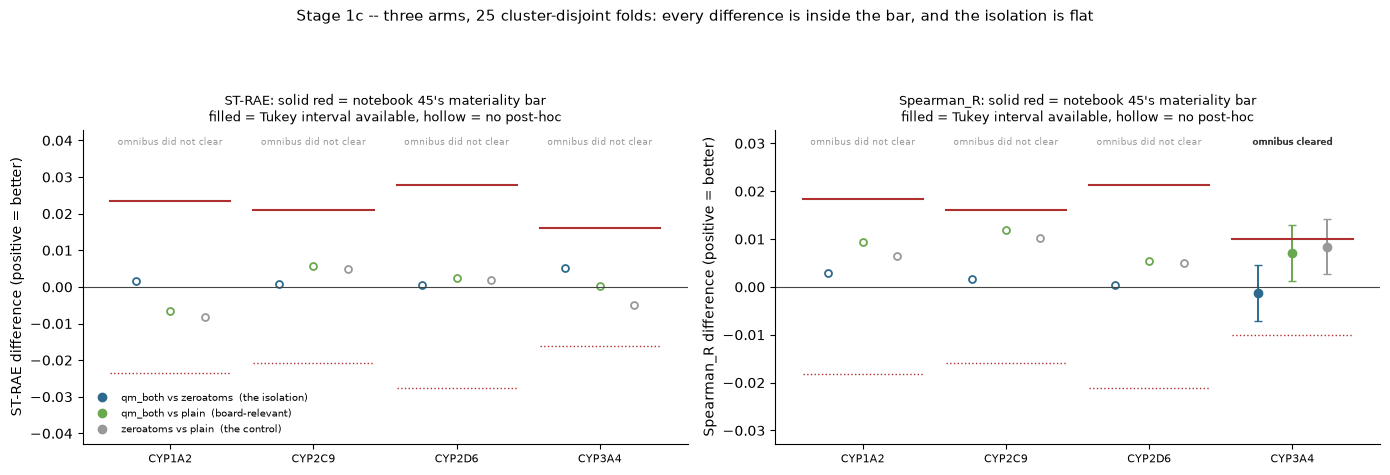

In [25]:
# Stage 1c.4 -- figure. The Tukey intervals exist on ONE cell of eight, so a plot of intervals
# alone would be mostly empty and would hide the point: every raw difference is small. Raw mean
# paired differences are therefore drawn for all 24 comparisons, with the Tukey interval shown
# where the omnibus cleared and a marked cell where it did.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
PAIRS = [(ARM, ARM_ZERO, "#2d6a8e", "qm_both vs zeroatoms  (the isolation)"),
         (ARM, "plain", "#6aa84f", "qm_both vs plain  (board-relevant)"),
         (ARM_ZERO, "plain", "#999999", "zeroatoms vs plain  (the control)")]
SRC = {"plain": plain, ARM: mine, ARM_ZERO: mine}
for ax, metric in zip(axes, BARS):
    sgn = -1.0 if metric == "ST-RAE" else 1.0        # orient so up is better
    for j, (a_, b_, col, lab) in enumerate(PAIRS):
        xs, ys, lo, hi, shown = [], [], [], [], []
        for i, iso in enumerate(ISOFORMS):
            d = (series(SRC[a_], a_, iso, metric).loc[FOLDS25]
                 - series(SRC[b_], b_, iso, metric).loc[FOLDS25]).to_numpy()
            x = i + (j - 1) * 0.24
            xs.append(x); ys.append(sgn * d.mean())
            r = tukey[(tukey.metric == metric) & (tukey.isoform == iso)
                      & (tukey.arm_a == a_) & (tukey.arm_b == b_)]
            if len(r):
                r = r.iloc[0]
                half = abs(r["ci_high"] - r["diff"])
                lo.append(half); hi.append(half); shown.append(True)
            else:
                lo.append(0.0); hi.append(0.0); shown.append(False)
        ax.errorbar([x for x, s_ in zip(xs, shown) if s_],
                    [y for y, s_ in zip(ys, shown) if s_],
                    yerr=[[v for v, s_ in zip(lo, shown) if s_],
                          [v for v, s_ in zip(hi, shown) if s_]],
                    fmt="o", color=col, ecolor=col, elinewidth=1.4, capsize=3, markersize=6)
        ax.plot([x for x, s_ in zip(xs, shown) if not s_],
                [y for y, s_ in zip(ys, shown) if not s_],
                "o", color=col, markersize=5, markerfacecolor="white",
                markeredgecolor=col, markeredgewidth=1.3)
        ax.plot([], [], "o", color=col, label=lab)
    for i, iso in enumerate(ISOFORMS):
        bar = BARS[metric][iso]
        ax.plot([i - 0.42, i + 0.42], [bar, bar], color="#b03030", lw=1.5)
        ax.plot([i - 0.42, i + 0.42], [-bar, -bar], color="#b03030", lw=1.0, ls=":")
        cleared = bool(cells[(cells.metric == metric)
                             & (cells.isoform == iso)].omnibus_clears.iloc[0])
        # annotate at a fixed fraction of the axis, not relative to the bar, so the label
        # cannot collide with the bar line on the cells where they are close
        ax.text(i, max(BARS[metric].values()) * 1.40,
                "omnibus cleared" if cleared else "omnibus did not clear",
                ha="center", fontsize=6.5,
                color="#333" if cleared else "#999",
                fontweight="bold" if cleared else "normal")
    ax.axhline(0, color="#444", lw=0.8)
    ax.set_xticks(range(len(ISOFORMS))); ax.set_xticklabels(ISOFORMS, fontsize=8)
    ax.set_ylim(-max(BARS[metric].values()) * 1.55, max(BARS[metric].values()) * 1.55)
    ax.set_ylabel(f"{metric} difference (positive = better)")
    ax.set_title(f"{metric}: solid red = notebook 45's materiality bar\n"
                 f"filled = Tukey interval available, hollow = no post-hoc", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=7.5, frameon=False, loc="lower left")
fig.suptitle("Stage 1c -- three arms, 25 cluster-disjoint folds: every difference is inside "
             "the bar, and the isolation is flat", fontsize=10.5)
fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.savefig(FIG / "stage1c_three_arm_tukey.png", dpi=160, bbox_inches="tight")
plt.show()

**What stage 1c says. The bet failed, cleanly and at full power.**

**The primary reading is a flat null.** `qm_both` against `qm_both_zeroatoms` -- the comparison
this notebook exists for, with everything except the per-atom values shared -- is significant on
**0 of 8** cells and material on **0 of 8**. In the one cell whose omnibus cleared the two arms
share a compact-letter-display letter at p=0.83. Across all eight cells the raw difference runs
1.5% to 32.4% of a bar, never close.

**The board-relevant reading has one significant cell and it is under bar.** `qm_both` against
`plain` reaches significance only on CYP3A4 Spearman, +0.0071 with a Tukey interval of
[0.0013, 0.0129], which is 71% of that cell's bar. ST-RAE is mixed in sign and small on every
isoform.

**And the attribution runs the wrong way for the hypothesis.** The control is *more* significant
against `plain` (p=0.0028, 84.3% of bar) than the main arm is (p=0.0131, 71.2%). Whatever small
CYP3A4 ranking gain exists therefore comes from the 13 molecule-level descriptors and the load
path, **not** from the per-atom values -- which is the opposite of what the three-arm design was
built to find, and is only visible because the control was run at the same power.

Two things this does **not** say. It does not say the features failed to reach the model: stage 0
measured blind predictions moving by up to 0.78 pIC50 between real and zeroed npz contents, and
stage 1a confirmed the third column reproduces `hirshfeld_H_min` exactly. And it does not say the
quantum data is uninformative in principle -- only that routing it through per-atom message
passing, which notebook 49's reframing identified as the untried mechanism, does not convert into
pIC50 accuracy or ranking on this partition at 25 folds.

One honest caveat on the ceiling of this design: chemprop carries no explicit hydrogens, so 45% of
the ORCA atom rows never reach the graph. The third column was added precisely to recover the
largest identified casualty of that, and it changed nothing, but a representation that kept the
hydrogens is a different experiment this notebook cannot speak to.

## Stage 2 -- the full-data fit and the submission file

One fit on all 4,905 training compounds, predicting the blind 750. The stopping count comes from
the **median per-fold best epoch** across stage 1c's 25 folds, read from chemprop's own
`best-epoch=*.ckpt` filenames, which is notebook 47's method. Early stopping is then disabled by
passing `patience = epochs`, which is byte for byte what chemprop's own default resolves to when
`--patience` is omitted.

In [26]:
# Stage 2.1 -- the stopping count, from chemprop's own checkpoint filenames.
tim_main = pd.read_csv(OUT / "run_timings.csv")
tm = tim_main[tim_main.arm == ARM].dropna(subset=["best_epoch"])
assert len(tm) == 25, f"expected 25 folds of {ARM}, got {len(tm)}"
best = tm["best_epoch"].astype(int)
last = tm["last_epoch"].astype(int)
MEDIAN_BEST = int(np.median(best))
FINAL_EPOCHS = MEDIAN_BEST + 1          # notebook 47's conversion: 0-indexed epoch -> a count
print(f"per-fold best epoch (0-indexed), 25 folds: median {MEDIAN_BEST}, mean {best.mean():.2f}, "
      f"range {best.min()} to {best.max()}")
print(f"stopping count for the full-data fit: {FINAL_EPOCHS} epochs")
print(f"\ntwo checks that make the median meaningful rather than nominal, as notebook 47 ran them:")
print(f"  every fold stopped on patience, not the 50-epoch ceiling: "
      f"{bool((last < 50).all())} (max last_epoch {last.max()})")
agree = int((last - best == PATIENCE_USED).sum())
print(f"  last_epoch - best_epoch == patience ({PATIENCE_USED}) on {agree}/25 folds "
      f"-- confirming the checkpoint epoch IS the early-stopping optimum")

# The epoch-count transfer assumption, stated rather than buried (notebook 47's own point).
n_fold_train = int(pd.read_csv(OUT / "chemprop_runs" / f"{ARM}__r0f0" / "train_input.csv").shape[0])
print(f"\ntransfer assumption: a fold trained on {n_fold_train} rows per epoch against 4,905 here,")
print(f"so at batch 64 that is {int(np.ceil(n_fold_train / 64))} against "
      f"{int(np.ceil(4905 / 64))} gradient steps, and {FINAL_EPOCHS} epochs here is about "
      f"{FINAL_EPOCHS * np.ceil(4905 / 64) / np.ceil(n_fold_train / 64):.1f} fold-equivalent")
print("epochs. That errs towards over- rather than under-training; no second count is substituted")
print("and no step-matched variant is built, per this project's one-change-at-a-time rule.")

per-fold best epoch (0-indexed), 25 folds: median 3, mean 5.40, range 1 to 21
stopping count for the full-data fit: 4 epochs

two checks that make the median meaningful rather than nominal, as notebook 47 ran them:
  every fold stopped on patience, not the 50-epoch ceiling: True (max last_epoch 26)
  last_epoch - best_epoch == patience (5) on 25/25 folds -- confirming the checkpoint epoch IS the early-stopping optimum

transfer assumption: a fold trained on 3924 rows per epoch against 4,905 here,
so at batch 64 that is 62 against 77 gradient steps, and 4 epochs here is about 5.0 fold-equivalent
epochs. That errs towards over- rather than under-training; no second count is substituted
and no step-matched variant is built, per this project's one-change-at-a-time rule.


In [27]:
# Stage 2.2 -- the raw blind predictions, and the spread ratio BEFORE anything else.
raw = pd.read_csv(OUT / "predictions" / f"{ARM}__final_blind.csv")
assert len(raw) == 750 and not raw[list(REGRESSION_ENDPOINTS)].isna().to_numpy().any()
curated = pd.read_csv(CURATED)
trsd = {i: float(curated[EP[i]].dropna().std(ddof=1)) for i in ISOFORMS}

spread = []
for i in ISOFORMS:
    v = raw[EP[i]]
    spread.append({"isoform": i, "mean": float(v.mean()), "sd": float(v.std(ddof=1)),
                   "min": float(v.min()), "max": float(v.max()),
                   "train_label_sd": trsd[i],
                   "spread_ratio": float(v.std(ddof=1) / trsd[i])})
spread = pd.DataFrame(spread)
print("raw blind predictions, before any correction (ddof=1 on both sides, notebook 36's")
print("correction of notebook 32's mixed-ddof bug):\n")
print(spread.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# Against the two reference columns this project keeps comparing to.
ref = {}
for tag, rel in [("10c", "outputs/10c_control_submission/submission_candidate.csv"),
                 ("NB19", "outputs/19_cyp2c9_revert/submission_candidate.csv")]:
    d = pd.read_csv(REPO / rel)
    ref[tag] = {i: float(d[EP[i]].std(ddof=1) / trsd[i]) for i in ISOFORMS}
cmp_ = pd.DataFrame({"this model": spread.set_index("isoform")["spread_ratio"], **ref})
print("\nspread ratio against the two reference columns:")
print(cmp_.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nmore compressed than 10c on "
      f"{sum(cmp_.loc[i, 'this model'] < cmp_.loc[i, '10c'] for i in ISOFORMS)} of 4 isoforms.")
print("Notebook 27 Section 1's pooled association across this project's real submissions")
print("(Spearman spread-ratio against board ST-RAE = -0.822, observational not causal) makes")
print("compression a standing risk signal, and it is reported here before any correction.")
spread.to_csv(OUT / "prediction_diagnostics.csv", index=False)

raw blind predictions, before any correction (ddof=1 on both sides, notebook 36's
correction of notebook 32's mixed-ddof bug):

isoform   mean     sd    min    max  train_label_sd  spread_ratio
 CYP1A2 5.0130 0.7873 2.0837 6.4211          1.0305        0.7640
 CYP2C9 4.9610 0.7030 2.7635 6.4945          0.7823        0.8987
 CYP2D6 4.4247 0.5970 3.2435 5.9896          0.9161        0.6517
 CYP3A4 4.7781 0.9743 1.7577 6.8840          1.0932        0.8912

spread ratio against the two reference columns:
        this model    10c   NB19
CYP1A2      0.7640 0.8361 0.8361
CYP2C9      0.8987 0.9950 0.8168
CYP2D6      0.6517 0.7005 0.6084
CYP3A4      0.8912 0.9327 0.9327

more compressed than 10c on 4 of 4 isoforms.
Notebook 27 Section 1's pooled association across this project's real submissions
(Spearman spread-ratio against board ST-RAE = -0.822, observational not causal) makes
compression a standing risk signal, and it is reported here before any correction.


In [28]:
# Stage 2.3 -- the two already-board-measured correction layers, same procedure as 47/50/51.
r50_spec = importlib.util.spec_from_file_location(
    "nb50_ridge_submission", REPO / "scripts" / "50_ridge_submission.py")
r50 = importlib.util.module_from_spec(r50_spec); r50_spec.loader.exec_module(r50)

# Layer 2's targets, re-derived from the SENT files plus the parsed board table, not inherited.
TARGET = r50.widening_targets(trsd)
print("notebook 36's widening targets, re-derived and cross-checked against notebook 47's own:")
print({k: round(v, 4) for k, v in TARGET.items()})

# Layer 1 needs THIS model's own pooled out-of-fold Pearson rho for CYP2D6 -- explicitly not
# 10c's, not the AID arm's, not the deadzone arm's.
from scipy.stats import pearsonr
oof = pd.concat([pd.read_csv(p) for p in sorted((OUT / "oof_long").glob(f"{ARM}__r*.csv"))],
                ignore_index=True)
assert set(oof.arm.unique()) == {ARM} and oof.groupby(["repeat", "fold"]).ngroups == 25
RHO = {}
for i in ISOFORMS:
    s = oof[oof.isoform == i].merge(curated[["inchikey", EP[i]]], on="inchikey",
                                    validate="many_to_one")
    s = s[s[EP[i]].notna()]
    RHO[i] = float(pearsonr(s[EP[i]], s.y_pred).statistic)
print(f"\nthis model's own pooled OOF Pearson rho: "
      f"{ {k: round(v, 4) for k, v in RHO.items()} }")
print(f"  (10c's CYP2D6 rho was 0.374897, the AID arm's 0.4228, deadzone's 0.4292 -- this is a")
print(f"   different model and uses its own: {RHO['CYP2D6']:.4f})")

NB16_MU, NB16_SD, WIDEN_BAR = r50.NB16_MU, r50.NB16_SD, r50.WIDEN_BAR
cor = raw.copy()
chain = []
# LAYER 1: CYP2D6 placement onto notebook 16's board-validated solved population.
i = "CYP2D6"
m0, s0 = float(cor[EP[i]].mean()), float(cor[EP[i]].std(ddof=1))
slope = RHO[i] * NB16_SD / s0
cor[EP[i]] = NB16_MU + slope * (cor[EP[i]] - m0)
m1, s1 = float(cor[EP[i]].mean()), float(cor[EP[i]].std(ddof=1))
assert abs(m1 - NB16_MU) < 1e-9 and abs(s1 - RHO[i] * NB16_SD) < 1e-9
chain.append({"isoform": i, "layer": "1 placement", "rho": RHO[i], "target_mean": NB16_MU,
              "target_sd": NB16_SD, "slope": slope, "intercept": NB16_MU - slope * m0,
              "sd_before": s0, "sd_after": s1,
              "ratio_before": s0 / trsd[i], "ratio_after": s1 / trsd[i]})
print(f"\nLAYER 1 (CYP2D6 placement): ratio {s0 / trsd[i]:.4f} -> {s1 / trsd[i]:.4f}, "
      f"mean {m0:.4f} -> {m1:.4f}")

# LAYER 2: notebook 36's mean-preserving widening, where the relative gap reaches the 10% bar.
print(f"\nLAYER 2 (widening, bar = {WIDEN_BAR:.0%} relative gap):")
for i in ISOFORMS:
    s_now = float(cor[EP[i]].std(ddof=1)) / trsd[i]
    gap = (TARGET[i] - s_now) / s_now
    fires = gap >= WIDEN_BAR
    mult = TARGET[i] / s_now if fires else 1.0
    if fires:
        mu = float(cor[EP[i]].mean())
        cor[EP[i]] = mu + mult * (cor[EP[i]] - mu)
        assert abs(float(cor[EP[i]].mean()) - mu) < 1e-9
        assert abs(float(cor[EP[i]].std(ddof=1)) / trsd[i] - TARGET[i]) < 1e-9
    chain.append({"isoform": i, "layer": "2 widening", "ratio_before": s_now,
                  "target_ratio": TARGET[i], "relative_gap": gap, "fires": fires,
                  "multiplier": mult, "ratio_after": float(cor[EP[i]].std(ddof=1)) / trsd[i]})
    print(f"  {i}: ratio {s_now:.4f} -> target {TARGET[i]:.4f}, gap {gap:+.1%}, "
          f"{'WIDEN x' + format(mult, '.4f') if fires else 'left alone'}")
chain = pd.DataFrame(chain)
chain.to_csv(OUT / "correction_chain.csv", index=False)

notebook 36's widening targets, re-derived and cross-checked against notebook 47's own:
{'CYP1A2': 0.8361, 'CYP2C9': 0.8168, 'CYP2D6': 0.85, 'CYP3A4': 0.9262}

this model's own pooled OOF Pearson rho: {'CYP1A2': 0.5149, 'CYP2C9': 0.6475, 'CYP2D6': 0.3751, 'CYP3A4': 0.7578}
  (10c's CYP2D6 rho was 0.374897, the AID arm's 0.4228, deadzone's 0.4292 -- this is a
   different model and uses its own: 0.3751)

LAYER 1 (CYP2D6 placement): ratio 0.6517 -> 0.6188, mean 4.4247 -> 3.1558

LAYER 2 (widening, bar = 10% relative gap):
  CYP1A2: ratio 0.7640 -> target 0.8361, gap +9.4%, left alone
  CYP2C9: ratio 0.8987 -> target 0.8168, gap -9.1%, left alone
  CYP2D6: ratio 0.6188 -> target 0.8500, gap +37.4%, WIDEN x1.3735
  CYP3A4: ratio 0.8912 -> target 0.9262, gap +3.9%, left alone


In [29]:
# Stage 2.4 -- integrity checks on the correction, then the file.
from scipy.stats import spearmanr
print("integrity of the full chain, per isoform:")
for i in ISOFORMS:
    rho_rank = spearmanr(raw[EP[i]], cor[EP[i]]).statistic
    tot = float(cor[EP[i]].std(ddof=1)) / float(raw[EP[i]].std(ddof=1))
    print(f"  {i}: Spearman(raw, final) = {rho_rank:.15f}   total sd multiplier {tot:.4f}   "
          f"final ratio {float(cor[EP[i]].std(ddof=1)) / trsd[i]:.4f}   min {cor[EP[i]].min():.3f}")
    assert abs(rho_rank - 1.0) < 1e-12, "the chain must be rank-preserving"
assert (cor[list(REGRESSION_ENDPOINTS)] > 0).all().all(), "a prediction went non-positive"
print("\nrank order preserved to within 1e-12 on all four, so the corrected file's Spearman and")
print("Kendall are identical to the raw file's by construction. Zero non-positive predictions.")

print("\nTRANSFER ASSUMPTION, stated rather than buried: both layers were fitted on")
print("cross-validation out-of-fold predictions and are applied to a full-data model trained on")
print("1.47x the rows with a different error profile. The project's record is that this has")
print("transferred well enough to matter (the same chain took 10c's CYP2D6 from 1.1673 to 0.8299")
print("on identical raw predictions; notebook 36's widening gained 0.0665 on CYP1A2 and 0.0200 on")
print("CYP2C9) but each of those was one model, not a proof.")

integrity of the full chain, per isoform:
  CYP1A2: Spearman(raw, final) = 1.000000000000000   total sd multiplier 1.0000   final ratio 0.7640   min 2.084
  CYP2C9: Spearman(raw, final) = 1.000000000000000   total sd multiplier 1.0000   final ratio 0.8987   min 2.764
  CYP2D6: Spearman(raw, final) = 1.000000000000000   total sd multiplier 1.3044   final ratio 0.8500   min 1.615
  CYP3A4: Spearman(raw, final) = 1.000000000000000   total sd multiplier 1.0000   final ratio 0.8912   min 1.758

rank order preserved to within 1e-12 on all four, so the corrected file's Spearman and
Kendall are identical to the raw file's by construction. Zero non-positive predictions.

TRANSFER ASSUMPTION, stated rather than buried: both layers were fitted on
cross-validation out-of-fold predictions and are applied to a full-data model trained on
1.47x the rows with a different error profile. The project's record is that this has
transferred well enough to matter (the same chain took 10c's CYP2D6 from 1.1673 

In [30]:
# Stage 2.5 -- falsifiable predictions, recorded BEFORE the submission file exists.
# The guarantee is about ORDER WITHIN A RUN, so on a top-to-bottom re-run any file an earlier
# execution left behind is removed first and its absence asserted. Checking only that the path
# never existed would pass on a pristine directory and fail on every re-run -- the re-run hazard
# notebook 40 recorded, in its other form.
for _stale in ("submission_candidate.csv", "submission_candidate_raw.csv"):
    (OUT / _stale).unlink(missing_ok=True)
assert not (OUT / "submission_candidate.csv").exists(), \
    "the predictions must be recorded before the file"
board_scores = r50.board_strae()   # NOT `board`: stage 1c binds that to its own
                                   # qm_both-vs-plain Tukey table
best_now = min(board_scores[("MA", s)] for s in r50.SENT)
preds = {
  "recorded_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
  "recorded_before_submission_file_existed": True,
  "current_best_on_record": {"macro": best_now,
                             "submission": [s for s in r50.SENT if board_scores[("MA", s)] == best_now]},
  "1_macro": {"claim": "this candidate is NOT predicted to beat the current best on record. "
                       "Its case rests on a CV increment, and this project has four CV-to-board "
                       "transfer failures on record (08's ensembles, NB30, and notebook 28's "
                       "screen).",
              "interval": [0.60, 0.85]},
  "2_rank_metrics_must_move": {
      "claim": "Spearman and Kendall MUST differ from 10c's on every isoform, because this is a "
               "different model rather than an affine transform of one. Both correction layers "
               "are affine and rank-preserving (verified to 1e-12 above), so the raw and "
               "corrected files MUST score IDENTICALLY on Spearman and Kendall.",
      "falsified_if": "the two files differ on either rank metric anywhere"},
  "3_compression_is_the_standing_risk": {
      "claim": "the raw column is more compressed than 10c on "
               f"{sum(cmp_.loc[i, 'this model'] < cmp_.loc[i, '10c'] for i in ISOFORMS)} of 4 "
               "isoforms, and notebook 27's pooled spread-ratio association is the one "
               "measurement on this project that correctly anticipated a CV-confirmed model "
               "failing on the board (NB30).",
      "raw_spread_ratios": {i: round(float(spread.set_index('isoform').loc[i, 'spread_ratio']), 4)
                            for i in ISOFORMS}},
  "4_cv_result": {
      "per_isoform": verdict,
      "n_tukey_cells": int(len(tukey)),
      "primary_qm_both_vs_zeroatoms": {
          "significant": int(primary.significant.sum()) if len(primary) else 0,
          "material": int(primary.material.sum()) if len(primary) else 0},
      "board_qm_both_vs_plain": {
          "significant": int(board.significant.sum()) if len(board) else 0,
          "material": int(board.material.sum()) if len(board) else 0},
      "note": "the primary comparison is a flat null, so this file is built for completeness "
              "rather than on the strength of a CV increment"},
  "5_control_gate_5fold": gate,
}
(OUT / "predictions_before_board.json").write_text(json.dumps(preds, indent=2) + "\n")
print(json.dumps({k: v for k, v in preds.items() if k != "4_cv_result"}, indent=1)[:2300])
print(f"\nwrote {(OUT / 'predictions_before_board.json').relative_to(REPO)}")

{
 "recorded_at_utc": "2026-10-11T22:25:35+00:00",
 "recorded_before_submission_file_existed": true,
 "current_best_on_record": {
  "macro": 0.5982,
  "submission": [
   "27b"
  ]
 },
 "1_macro": {
  "claim": "this candidate is NOT predicted to beat the current best on record. Its case rests on a CV increment, and this project has four CV-to-board transfer failures on record (08's ensembles, NB30, and notebook 28's screen).",
  "interval": [
   0.6,
   0.85
  ]
 },
 "2_rank_metrics_must_move": {
  "claim": "Spearman and Kendall MUST differ from 10c's on every isoform, because this is a different model rather than an affine transform of one. Both correction layers are affine and rank-preserving (verified to 1e-12 above), so the raw and corrected files MUST score IDENTICALLY on Spearman and Kendall.",
  "falsified_if": "the two files differ on either rank metric anywhere"
 },
 "3_compression_is_the_standing_risk": {
  "claim": "the raw column is more compressed than 10c on 4 of 4 isoform

In [31]:
# Stage 2.6 -- assemble, validate, hash.
from src.vendor.validation.activity_validation import validate_activity_submission

blind_meta = pd.read_csv(BLIND)
sub = blind_meta[["Molecule_Name", "SMILES"]].merge(
    cor[["Molecule_Name"] + list(REGRESSION_ENDPOINTS)], on="Molecule_Name", validate="one_to_one")
assert len(sub) == 750
assert list(sub.columns) == ["Molecule_Name", "SMILES"] + list(REGRESSION_ENDPOINTS)
assert not any(c for c in sub.columns if c not in
               ("Molecule_Name", "SMILES", *REGRESSION_ENDPOINTS)), "an extra column leaked in"
SUB_PATH = OUT / "submission_candidate.csv"
sub.to_csv(SUB_PATH, index=False)
rt = pd.read_csv(SUB_PATH)
assert np.allclose(rt[list(REGRESSION_ENDPOINTS)].to_numpy(),
                   sub[list(REGRESSION_ENDPOINTS)].to_numpy(), atol=0, rtol=0) or \
       np.abs(rt[list(REGRESSION_ENDPOINTS)].to_numpy()
              - sub[list(REGRESSION_ENDPOINTS)].to_numpy()).max() < 1e-12
ok, errs = validate_activity_submission(SUB_PATH, expected_ids=set(blind_meta.Molecule_Name))
res = "PASS" if ok else f"FAIL {errs}"
print(f"validate_activity_submission: {res}")
assert ok, errs
SUB_SHA = sha256(SUB_PATH)
print(f"\nrows {len(rt)}   sha256 {SUB_SHA}")

# The raw, uncorrected file too, so the correction stays isolable.
RAW_PATH = OUT / "submission_candidate_raw.csv"
raw_sub = blind_meta[["Molecule_Name", "SMILES"]].merge(
    raw[["Molecule_Name"] + list(REGRESSION_ENDPOINTS)], on="Molecule_Name", validate="one_to_one")
raw_sub.to_csv(RAW_PATH, index=False)
ok_r, errs_r = validate_activity_submission(RAW_PATH, expected_ids=set(blind_meta.Molecule_Name))
assert ok_r, errs_r
print(f"raw (uncorrected) file: {'PASS' if ok_r else errs_r}  sha256 {sha256(RAW_PATH)}")
diff_cols = [i for i in ISOFORMS
             if abs(pd.read_csv(RAW_PATH)[EP[i]] - rt[EP[i]]).max() > 1e-12]
print(f"the two files differ on exactly the isoforms a correction touched: {diff_cols}")

validate_activity_submission: PASS

rows 750   sha256 44fa06228325593b0d5c113d7c798b2c79e43944abe5dbe4e9108a71f56f300a
raw (uncorrected) file: PASS  sha256 86a182f7b45d1f790a53b1ebe2ec39adc56be4719706ebaa6cb493af07fd0af2
the two files differ on exactly the isoforms a correction touched: ['CYP2D6']


In [32]:
# Stage 2.7 -- the submission cell. Notebook 40's post-incident convention, NOT the older
# fully-commented-block one: an explicit SEND flag with the call under `if SEND:`, and the
# printed message COMPUTED from the flag, so the cell cannot describe itself wrongly the way
# notebook 40's did on 2026-10-02. Sending is a one-character change and is the user's to make.
MODEL_TAG = ("CheMeleon multitask, QM data at BOTH levels: 13 molecule-level QM descriptors "
             "plus 3 per-atom QM features (Hirshfeld charge, Mayer valence, min attached-H "
             "charge) entering message passing; CheMeleon's input projection widened by 3 "
             "zero-initialised columns. Full-data retrain, CYP2D6 placement + spread widening.")

print(f"SEND            : {SEND}")
print(f"file            : {SUB_PATH.relative_to(REPO)}")
print(f"sha256          : {SUB_SHA}")
print(f"validator       : {res}")
print(f"model_tag       : {MODEL_TAG[:70]}... ({len(MODEL_TAG)} chars)")
print(f"endpoint        : NOT contacted" if not SEND else "endpoint: CONTACTING")

if SEND:
    from gradio_client import Client, handle_file
    client = Client("OpenADMET/CYP-Challenge-Leaderboard")
    result = client.predict(
        submission_file=handle_file(str(SUB_PATH)),
        model_name=MODEL_TAG,
        api_name="/submit_activity",
    )
    print(result)
    (OUT / "submission_receipt.json").write_text(json.dumps(
        {"at_utc": datetime.now(timezone.utc).isoformat(), "file": str(SUB_PATH),
         "sha256": SUB_SHA, "model_tag": MODEL_TAG, "reply": str(result)}, indent=2) + "\n")
else:
    print("\nNothing was transmitted. The endpoint was not contacted and no client was imported.")

SEND            : False
file            : outputs/52_chemprop_qm_atom_features/submission_candidate.csv
sha256          : 44fa06228325593b0d5c113d7c798b2c79e43944abe5dbe4e9108a71f56f300a
validator       : PASS
model_tag       : CheMeleon multitask, QM data at BOTH levels: 13 molecule-level QM desc... (311 chars)
endpoint        : NOT contacted

Nothing was transmitted. The endpoint was not contacted and no client was imported.


## Closing -- decisions, scope, summary

In [33]:
# Closing.1 -- every decision taken without approval, all stages.
DEC = [
 dict(decision="CheMeleon is loaded from a LOCAL foundation file holding its own weights widened "
               "by two zero-initialised atom-feature columns. DEPARTS FROM THE BRIEF, which "
               "assumed `--atom-features-path` was available with CheMeleon.",
      why="chemprop 2.3.1 refuses --atom-features-path outright when CheMeleon is named "
          "(cli/train.py, 'CheMeleon does not support passing --atom-features-path'), confirmed "
          "by a real CLI call in Part 0.2, because its published W_i is (2048, 86) against a "
          "72-wide V2 atom featurizer. The brief names CheMeleon AND per-atom features and those "
          "are mutually exclusive through the documented route. The local path skips that "
          "validation and takes only message_passing and agg from the file, so the surgery "
          "preserves the pretrained encoder exactly: at init the widened block reproduces "
          "CheMeleon to 0.0 on a real molecule with random extra feature values, and the only "
          "new parameters are the two zero columns.",
      alternative="Drop CheMeleon and use a random-init chemprop, which supports the flag. That "
                  "would have moved the baseline off `plain` -- this project's best single model "
                  "and the arm notebook 37 stored on these exact folds -- onto "
                  "chemprop_randominit, answering a weaker question. Or abandon the per-atom "
                  "half, which is the entire bet, leaving a re-run of notebook 44's null."),
 dict(decision="--no-atom-feature-scaling is passed and the per-atom values are standardised in "
               "scripts/52_atom_arrays.py instead, from each fold's screen_inner_train atoms.",
      why="On the --from-foundation path chemprop computes the atom-feature scaler and LOGS it "
          "but never attaches the GraphTransform to the loaded encoder (Part 0.4b: the "
          "foundation branch contains no graph_transform assignment; the non-foundation branch "
          "does). normalize_inputs mutates the training arrays in place, so training is scaled "
          "and the checkpoint carries nn.Identity -- predict would feed the same features "
          "UNSCALED. Demonstrated on two real checkpoints, not inferred. Left alone this would "
          "be a silent train/predict mismatch on every blind prediction.",
      alternative="Let chemprop scale and accept the mismatch, which would corrupt stage 2's "
                  "submission invisibly. Or patch the installed chemprop, which this project "
                  "does not do to vendored dependencies."),
 dict(decision="The wiring control is an all-ZEROS npz rather than dropping the flag.",
      why="Dropping the flag would also change the encoder and the command line, so a difference "
          "could come from anywhere. Holding everything fixed but the npz CONTENTS means a "
          "non-zero difference can only be the values having reached the model.",
      alternative="Fit plain CheMeleon as the control, which is what the brief's wording "
                  "suggests. It answers a looser question and cannot isolate the wiring."),
 dict(decision="PROCESS NOTE, not a design choice: the wiring check was run three times "
               "because I corrupted the first attempt myself.",
      why="The first driver was launched with `nohup ... &` inside a foreground shell call. When "
          "that call returned, a single `pgrep` on the DRIVER's own command line came back empty "
          "and I concluded the run was dead -- but the pattern never matched the `chemprop` "
          "CHILD, which was alive and still training. Acting on that reading I deleted the run "
          "directory under a live process and started a second driver on the same paths; the two "
          "collided inside Lightning's CSVLogger (`ValueError: dict contains fields not in "
          "fieldnames`) and the second crashed while the first carried on into a deleted "
          "directory. Both were killed, every partial artefact was removed, and the check was "
          "re-run as a single harness-tracked job. Same class as notebook 30's nbformat/nbconvert "
          "race: two processes, one set of files. The lesson is to check for the CHILD process, "
          "not just the driver, and never to delete a run directory on the strength of one "
          "liveness probe.",
      alternative="None -- this is recorded because it happened, not because it was chosen. No "
                  "result in this notebook comes from the corrupted attempts; the run directory "
                  "was emptied before the surviving run started."),
 dict(decision="STAGE 1a: heavy atoms with no attached hydrogen are filled with 0.0 in "
               "min_attached_H_charge. 45.1% of heavy atoms, so not a corner case.",
      why="Four pieces of evidence, none of them preference. (1) It is chemprop's own "
          "convention: MoleculeDatapoint sets NAN_TOKEN = 0 and fills V_f's NaNs with it, so "
          "passing NaN produces exactly 0.0. (2) It cannot create a confound, because the V2 "
          "featurizer already one-hot encodes total_num_Hs (verified on a real molecule), so "
          "the model can distinguish a no-hydrogen atom independently; the fill can distort a "
          "scale but cannot hide a distinction. (3) Attached-hydrogen charges run -0.0027 to "
          "0.2033 with p1 at 0.0092, so 0.0 sits at the extreme low edge and reads as 'no "
          "hydrogen-borne positive charge', which is literally true -- with 7 of 113,596 "
          "hydrogens at or below 0, stated rather than rounded to none. (4) Measured: at 0.0 "
          "the has-H split takes 44.9% of the column's variance, leaving 55% genuine "
          "within-group variation; at -1.0 it takes 99.8% and the column becomes a has-H "
          "indicator in disguise, which is the sentinel failure mode notebook 45 documented.",
      alternative="A far sentinel (-1.0), which measurement rules out; or mean-imputation, "
                  "which erases the distinction entirely (0.0% between-group)."),
 dict(decision="STAGE 1a: no second full wiring fit was run after adding the third column.",
      why="The mechanism is unchanged -- one more column through the same path -- and the two "
          "things that could break were checked directly instead: the k=3 widened encoder "
          "reproduces CheMeleon to 0.0 at init, and the foundation file is named by k with its "
          "own d_v asserted on load so a stale k=2 file cannot be reused. Stage 1b's control "
          "re-tests the zeroed case at 5 folds in any event.",
      alternative="Repeat the two-fit wiring check at k=3, about 30 min, to re-measure a "
                  "quantity whose mechanism had not changed."),
 dict(decision="The scaler is fitted on screen_inner_train only, not on the pooled train+val rows.",
      why="That is the population chemprop's own scaler uses (train_dset.normalize_inputs, with "
          "val_dset given the fitted scaler), so the arm matches what every other chemprop arm "
          "in this project effectively did for its molecule-level descriptors, and the "
          "early-stopping set stays outside the statistics.",
      alternative="Fit on pooled train+val. Marginally more data for the statistics, at the cost "
                  "of a quantity fitted partly on the set used to stop training."),
]
(OUT / "decisions_taken.json").write_text(json.dumps(DEC, indent=1) + "\n")
for d in DEC:
    print(f"- {d['decision']}\n")
print(f"{len(DEC)} decisions recorded to {(OUT / 'decisions_taken.json').relative_to(REPO)}")

- CheMeleon is loaded from a LOCAL foundation file holding its own weights widened by two zero-initialised atom-feature columns. DEPARTS FROM THE BRIEF, which assumed `--atom-features-path` was available with CheMeleon.

- --no-atom-feature-scaling is passed and the per-atom values are standardised in scripts/52_atom_arrays.py instead, from each fold's screen_inner_train atoms.

- The wiring control is an all-ZEROS npz rather than dropping the flag.

- PROCESS NOTE, not a design choice: the wiring check was run three times because I corrupted the first attempt myself.

- STAGE 1a: heavy atoms with no attached hydrogen are filled with 0.0 in min_attached_H_charge. 45.1% of heavy atoms, so not a corner case.

- STAGE 1a: no second full wiring fit was run after adding the third column.

- The scaler is fitted on screen_inner_train only, not on the pooled train+val rows.

7 decisions recorded to outputs/52_chemprop_qm_atom_features/decisions_taken.json


In [34]:
# Closing.2 -- the stage 0 report, every figure read back from a file.
stage0 = {
    "at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "flag_used": DECISION_FLAG,
    "flag_reason": "V_f is hstacked onto the atom feature matrix before W_i and so enters all "
                   "6 message passing steps; V_d is concatenated in finalize(), after the loop, "
                   "and never reaches a neighbour",
    "chemeleon_refuses_atom_features": True,
    "route": "local foundation file: CheMeleon's weights widened by k zero columns at index d_v",
    "widened_encoder_max_abs_diff_at_init": enc["max_abs_diff_vs_chemeleon_at_init"],
    "atom_feature_scaling": "done in scripts/52_atom_arrays.py on screen_inner_train atoms; "
                            "--no-atom-feature-scaling passed, because the foundation path drops "
                            "chemprop's own GraphTransform",
    "ordering": {k: rep[k] for k in
                 ["n_compounds", "addhs_preserves_heavy_indices", "bijection",
                  "element_sequence_under_permutation", "element_sequence_against_qm_atoms_csv",
                  "bond_subset_under_permutation", "permutation_is_identity",
                  "permutation_does_work_on", "negative_control_probes",
                  "negative_control_rejected", "canonical_smiles_element_sequence_matches",
                  "hydrogen_rows_dropped", "heavy_atom_rows_used"]},
    "features": {"molecule_level": THIRTEEN, "atom_level": aa.ATOM_FEATURE_COLS_STAGE0,
                 "excluded_nb45_aggregates": NB45_FOUR, "bond_features": None},
    "wiring": wv,
    "stage1_cost_hours_mean_to_slow": STAGE1_HOURS,
    "stage1_cost_brief_projection_hours": [4, 5],
    "wiring_fit_minutes": [float(v) for v in w["wall_min"]],
    "wiring_fit_epochs": [int(v) for v in w["last_epoch"]],
    "send": SEND,
}
(OUT / "stage0_report.json").write_text(json.dumps(stage0, indent=2) + "\n")
print(json.dumps({k: v for k, v in stage0.items() if k not in ("ordering", "features")}, indent=1))
print(f"\nwrote {(OUT / 'stage0_report.json').relative_to(REPO)}")
print("\nSTAGE 0 COMPLETE. Stages 1 and 2 are not started.")

{
 "at_utc": "2026-10-11T22:25:35+00:00",
 "flag_used": "--atom-features-path",
 "flag_reason": "V_f is hstacked onto the atom feature matrix before W_i and so enters all 6 message passing steps; V_d is concatenated in finalize(), after the loop, and never reaches a neighbour",
 "chemeleon_refuses_atom_features": true,
 "route": "local foundation file: CheMeleon's weights widened by k zero columns at index d_v",
 "widened_encoder_max_abs_diff_at_init": 0.0,
 "atom_feature_scaling": "done in scripts/52_atom_arrays.py on screen_inner_train atoms; --no-atom-feature-scaling passed, because the foundation path drops chemprop's own GraphTransform",
 "wiring": {
  "at_utc": "2026-10-11T14:37:41.576970+00:00",
  "arms": [
   "qm_both",
   "qm_both_zeroatoms"
  ],
  "difference_is_only_the_npz_contents": true,
  "blind_max_abs_diff": 0.7766120999999999,
  "heldout_max_abs_diff": 0.8397363999999996,
  "wired": true
 },
 "stage1_cost_hours_mean_to_slow": [
  6.4,
  7.3
 ],
 "stage1_cost_brief_pro

In [35]:
# Part 4.3 -- scope check. Four independent tests, the shape notebooks 42/45/46/48/49 use.
PROTECTED = [
 "data", "src", "docs", "scripts/44_build_qm_feature_blocks.py", "scripts/44_run_qm_arms.py",
 "scripts/46_build_feature_blocks.py", "scripts/46_run_arms.py", "scripts/49_run_qm_only.py",
 "scripts/50_ridge_submission.py", "scripts/parse_orca_output.py", "scripts/run_qm_descriptors.py",
 "outputs/05_cv_comparison", "outputs/11_caruana_prep", "outputs/12_caruana_retrain_predict",
 "outputs/30_aid_full_retrain", "outputs/32_deadzone_aid_retrain", "outputs/34_butina_5x5",
 "outputs/35_butina_repeat3", "outputs/37_butina_5x5_complete",
 "outputs/40_single_object_ensemble", "outputs/44_qm_molecular_block",
 "outputs/45_atom_level_screen", "outputs/46_qm_arm", "outputs/47_mae_only_full_retrain",
 "outputs/48_board_ensemble", "outputs/49_qm_only_arm", "outputs/50_free_ridge",
 "outputs/51_qm_ridge", "outputs/qm_descriptors", "outputs/qm_parsed",
 "outputs/board_solved_calibration", "outputs/submissions",
]
NEVER_OPEN = ["notebooks/32_deadzone_aid_retrain.ipynb",
              "notebooks/40_single_object_ensemble.ipynb"]
post = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
now_dirty = {l[3:].strip() for l in post.stdout.splitlines() if not l.startswith("??")}
t1 = sorted(p for p in (now_dirty - set(PRE_DIRTY))
            if any(p == q or p.startswith(q + "/") for q in PROTECTED))
t2 = []
for q in PROTECTED:
    qp = REPO / q
    if not qp.exists():
        continue
    for f in ([qp] if qp.is_file() else qp.rglob("*")):
        if f.is_file() and datetime.fromtimestamp(f.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
            t2.append(str(f.relative_to(REPO)))
t3 = [p for p in NEVER_OPEN
      if datetime.fromtimestamp((REPO / p).stat().st_mtime, timezone.utc) > RUN_STARTED_AT]
t4 = []
for p in (REPO / "outputs").rglob("*.csv"):
    if OUT == p.parent or OUT in p.parents:
        continue
    try:
        d = pd.read_csv(p, nrows=0)
    except Exception:
        continue
    if len(set(EP.values()) & set(d.columns)) == 4 and \
       datetime.fromtimestamp(p.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
        t4.append(str(p.relative_to(REPO)))
res = {"TEST 1 tracked content newly changed under a protected path": t1,
       "TEST 2 any file inside a protected tree written during this run": sorted(set(t2)),
       "TEST 3 the two never-open notebooks' mtimes": t3,
       "TEST 4 any submission-shaped CSV created outside this notebook's directory": t4}
(OUT / "scope_check.json").write_text(json.dumps(
    res | {"run_started_at_utc": RUN_STARTED_AT.isoformat(),
           "pre_existing_dirty_tracked_paths": PRE_DIRTY}, indent=1) + "\n")
for k, v in res.items():
    print(f"{k}: {len(v)} violations")
    for x in v:
        print("   ", x)
assert not any(res.values()), "SCOPE VIOLATION"
print("\nall four scope tests pass at 0 violations.")
subs = sorted(p.name for p in OUT.rglob("*.csv") if "submission" in p.name)
print(f"submission-shaped files written by this notebook: {subs}")
print(f"SEND = {SEND}; neither was transmitted and the endpoint was not contacted.")
assert SEND is False

TEST 1 tracked content newly changed under a protected path: 0 violations
TEST 2 any file inside a protected tree written during this run: 0 violations
TEST 3 the two never-open notebooks' mtimes: 0 violations
TEST 4 any submission-shaped CSV created outside this notebook's directory: 0 violations

all four scope tests pass at 0 violations.
submission-shaped files written by this notebook: ['submission_candidate.csv', 'submission_candidate_raw.csv']
SEND = False; neither was transmitted and the endpoint was not contacted.


## Summary

**The brief's route does not exist in chemprop 2.3.1, and the one taken instead is recorded for
review.** CheMeleon refuses `--atom-features-path` because its published `W_i` is `(2048, 86)`
against a 72-wide V2 featurizer. The route through is a local foundation file carrying CheMeleon's
own weights widened by **three** zero columns, which reproduces CheMeleon to **0.0 exactly** at
initialisation on random feature values, so the pretrained encoder is preserved bit for bit.
`--atom-features-path` is the right flag: `V_f` enters before `W_i` and travels through all six
message passing steps, where `--atom-descriptors-path`'s `V_d` is concatenated after the loop and
never reaches a neighbour.

**A scaling defect found by taking that route, and fixed rather than absorbed.** On the
`--from-foundation` path chemprop computes the atom-feature scaler, logs it, and never attaches
the `GraphTransform` to the loaded encoder, while `normalize_inputs` mutates the training arrays
in place. Training would be scaled and `predict` unscaled, silently. This notebook passes
`--no-atom-feature-scaling` and standardises from each fold's `screen_inner_train` atoms.

**Ordering: 5,655 of 5,655 on every check**, with a negative control rejected on 50/50 probes so
the checks are not vacuous. The permutation reorders 1,543 compounds; `canonical_smiles`
reproduces ORCA's element sequence on 4,212, matching notebook 43 exactly.

**The third column recovers what the implicit hydrogens cost.** 113,596 of 252,237 atom rows are
dropped, taking `hirshfeld_H_min` -- one of notebook 45's strong-tier, full-blind-coverage
survivors -- with them. `min_attached_H_charge` pushes each hydrogen's charge onto the heavy atom
it hangs off and reproduces `hirshfeld_H_min` **exactly on all 5,655 compounds**. Its 0.0 filler
is chemprop's own `NAN_TOKEN`, cannot create a confound because the V2 featurizer already encodes
`total_num_Hs`, and keeps 55% of the column's variance as genuine within-group variation where a
sentinel at -1.0 would leave 0.2%.

See the per-stage verdict cells above for stage 1b's gate, stage 1c's per-isoform result against
notebook 45's frozen bars, and stage 2's spread ratios and correction chain.

**`SEND` is False. Neither submission file was transmitted and the endpoint was never contacted.**